# Предобработка данных и регрессия на датасете «House Prices»

**Дисциплина:** Машинное обучение и ИИ  
**Модуль 2:** Предобработка данных и базовые алгоритмы регрессии/классификации  
**Датасет:** House Prices — Advanced Regression Techniques  
**Выполнил:** Команич Роман Маркович  
**Группа:** АСОиУб-23-2  
**Преподаватель:** Спирин Игорь Сергеевич  
**Ссылка на репозиторий:** https://github.com/KomanichRoman/ml-course-komanich.git  
**Путь к модулю:** `module-2-house-prices/notebook.ipynb`  
**Дата сдачи:** 2026-10-13

## Введение

### Какую задачу решаем?

Мы решаем задачу **регрессии** — предсказать цену продажи жилого дома (`SalePrice`) на основе 79 признаков: площадь, качество, год постройки, район, состояние гаража и так далее. Целевая переменная `SalePrice` — непрерывная величина в долларах, от $34 900 до $755 000.

### Что такое ML-проект?

**ML-проект** — это последовательность этапов, которая превращает сырые данные в работающую модель. Жизненный цикл включает: сбор и загрузку данных → разведочный анализ (EDA) → предобработку (пропуски, выбросы, кодирование, масштабирование) → создание новых признаков (Feature Engineering) → обучение моделей → оценку качества → интерпретацию результатов → сохранение модели и её деплой. Каждый этап влияет на итоговое качество: пропустишь обработку пропусков — модель не обучится, проигнорируешь выбросы — получишь смещённые веса.

### Почему это регрессия, а не классификация?

**Регрессия** предсказывает **непрерывную величину** — результат может быть любым числом из диапазона (например, $250 000 или $187 500). **Классификация** предсказывает **дискретную метку класса** — результат ограничен конечным набором значений (например, «выжил / не выжил» или «спам / не спам»).

В нашей задаче ответ на вопрос «сколько стоит дом?» — это число в долларах, а не метка класса. Поэтому это **регрессия**.

### Какая метрика важнее в этой задаче?

Для задачи House Prices основная метрика — **RMSE (Root Mean Squared Error)**, потому что она измеряется в тех же единицах, что и целевая переменная (в долларах), и её легко интерпретировать: «модель в среднем ошибается на $25 000». RMSE штрафует большие ошибки сильнее, чем MAE, что важно при прогнозе цен — ошибиться на $100 000 хуже, чем ошибиться на $10 000 в 10 раз.

- **MAE** — медианная ошибка, устойчива к выбросам, но не так чувствительна к крупным промахам.
- **R²** — доля объяснённой дисперсии, безразмерная метрика, удобна для сравнения моделей, но не говорит, на сколько долларов ошибается модель.

**Итог:** основная метрика — **RMSE**, вспомогательные — **MAE** и **R²**.

### Цель работы

Сформулируем 3 конкретных цели:

1. **Провести полный EDA** датасета House Prices: анализ пропусков, распределения целевой переменной, выбросов, корреляций, категориальных признаков.
2. **Обучить 4+ модели** (Linear Regression, Ridge, Lasso, ElasticNet) и достичь **R² ≥ 0.90** на тестовой выборке.
3. **Реализовать функцию предсказания** цены нового дома на основе его характеристик и продемонстрировать её работу на 5+ примерах.

## Теоретическая часть

### Регрессия

**Регрессия** — это класс задач машинного обучения с учителем, в которых целевая переменная является непрерывной величиной. Модель учится предсказывать число, а не метку класса. Примеры: предсказание цены дома, температуры, курса валют. Ключевое отличие от классификации: в регрессии целевая переменная непрерывна (например, $250 000), в классификации — дискретна (например, 0 или 1). Метрики регрессии: RMSE, MAE, R². Метрики классификации: Accuracy, Precision, Recall, F1.

### Пропуски (NaN)

**Пропуски** — это отсутствующие значения в данных, обозначаемые как `NaN` (Not a Number). Возникают по трём причинам: данные не были собраны изначально, потерялись при оцифровке, или произошла ошибка при вводе. В House Prices пропуски не случайны: `PoolQC = NaN` означает «нет бассейна», а `LotFrontage = NaN` — «данные не собраны». Методичка выделяет три типа пропусков:

- **MCAR (Missing Completely At Random)** — пропуск не зависит ни от чего. Редкий случай.
- **MAR (Missing At Random)** — пропуск зависит от других признаков. Пример: `LotFrontage` зависит от `Neighborhood`.
- **MNAR (Missing Not At Random)** — пропуск зависит от самого значения. Пример: `PoolQC = NaN`, потому что нет бассейна.

Стратегии обработки: смысловые пропуски (MNAR) → «None» или 0, случайные (MAR) → медиана по группам, оставшиеся → мода/медиана.

### Регуляризация

**Регуляризация** — это добавление штрафа за большие веса к функции потерь. Применяется, когда признаков много и OLS-решение переобучается: модель запоминает шум в обучающих данных и плохо работает на новых.

- **Ridge (L2)** — штраф $\alpha \sum w_j^2$. Веса уменьшаются, но не обнуляются. Хорошо работает при мультиколлинеарности.
- **Lasso (L1)** — штраф $\alpha \sum |w_j|$. Некоторые веса точно обнуляются, выполняется автоматический отбор признаков.
- **ElasticNet** — комбинация L1 и L2. Компромисс между Ridge и Lasso.

Чем больше $\alpha$, тем сильнее штраф. При $\alpha \to 0$ получаем OLS, при $\alpha \to \infty$ все веса → 0.

### Логарифмирование

**Логарифмирование** — это преобразование скошенной целевой переменной для приближения её распределения к нормальному. `SalePrice` имеет правую асимметрию (skew ≈ 1.88): большинство домов дешёвые, но есть несколько очень дорогих. Последствия для регрессии: нарушение нормальности остатков, гетероскедастичность, большое влияние выбросов. Решение — `log1p`:

$$y' = \log(1 + y)$$

Обратное преобразование — `expm1`:

$$y = \exp(y') - 1$$

После `log1p` skew падает с 1.88 до ≈ 0.12 — распределение становится почти нормальным.

### Feature Engineering

**Feature Engineering** — это создание новых признаков на основе существующих, чтобы помочь модели найти закономерности. Хорошие признаки могут повысить качество сильнее, чем смена алгоритма. Для House Prices создаём: `TotalSF` (сумма площадей), `TotalBath` (взвешенное число ванных), `HouseAge` (возраст дома), `HasPool` (бинарный признак наличия бассейна), `OverallQual_TotalSF` (взаимодействие качества и площади). Эти признаки несут больше смысла, чем исходные столбцы.

### Метрики регрессии

**Метрики регрессии** показывают, насколько хорошо модель предсказывает непрерывную величину.

- **MSE (Mean Squared Error)** — среднеквадратичная ошибка. Штрафует большие ошибки сильнее, чувствительна к выбросам. Единицы — квадрат целевой.
- **RMSE (Root Mean Squared Error)** — корень из MSE. В тех же единицах, что и целевая: «средняя ошибка в долларах». Чувствительна к выбросам.
- **MAE (Mean Absolute Error)** — средняя абсолютная ошибка. Устойчива к выбросам, соответствует медианной ошибке.
- **R² (Coefficient of Determination)** — доля объяснённой дисперсии. Безразмерная, сравнивает модели между собой. Может быть отрицательной, если модель хуже среднего.

Формулы метрик:

$$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

$$RMSE = \sqrt{MSE} \quad MAE = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$

$$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

### Сравнение регрессии и классификации

| Аспект | Регрессия | Классификация |
|--------|-----------|---------------|
| Целевая переменная | Непрерывная (цена, температура) | Дискретная (класс, метка) |
| Пример | `SalePrice = $250 000` | `Survived = 0 или 1` |
| Метрики | RMSE, MAE, R² | Accuracy, Precision, Recall, F1 |
| Выход модели | Число из диапазона | Вероятность класса |

## Описание данных

В этом разделе загрузим датасет House Prices, изучим его структуру, типы признаков, распределение целевой переменной и первичную статистику.

In [1]:
# ============================================================
# Раздел 4. Описание данных
# ============================================================

# Импорт библиотек для работы с данными
import pandas as pd
import numpy as np
import os

# Создаём папку data/, если её нет.
# В Colab файлы из /content удаляются при перезапуске,
# поэтому этот код нужен при каждом старте сессии.
os.makedirs('data', exist_ok=True)

# Переносим train.csv и test.csv из корня /content в data/,
# если они загружены в корень. Так структура соответствует
# репозиторию (module-2-house-prices/data/).
if os.path.exists('train.csv') and not os.path.exists('data/train.csv'):
    os.rename('train.csv', 'data/train.csv')
if os.path.exists('test.csv') and not os.path.exists('data/test.csv'):
    os.rename('test.csv', 'data/test.csv')

# Загрузка тренировочной выборки.
# train.csv содержит 1460 строк и 81 столбец:
#   - 79 признаков
#   - Id (идентификатор)
#   - SalePrice (целевая переменная, только в train).
train_df = pd.read_csv('data/train.csv')

# Загрузка тестовой выборки.
# test.csv содержит 1459 строк и 80 столбцов:
#   - 79 признаков + Id
#   - целевой переменной SalePrice здесь нет.
test_df = pd.read_csv('data/test.csv')

# Размеры датасетов — обязательный вывод по методичке
print("=" * 60)
print("РАЗМЕРЫ ДАТАСЕТОВ")
print("=" * 60)
print(f"train_df: {train_df.shape}")
print(f"test_df:  {test_df.shape}")

# Первые 5 строк train — визуальная проверка загрузки
print("\n" + "=" * 60)
print("ПЕРВЫЕ 5 СТРОК train_df")
print("=" * 60)
print(train_df.head())

# Типы данных и пропуски
print("\n" + "=" * 60)
print("ТИПЫ ДАННЫХ И ПРОПУСКИ")
print("=" * 60)
train_df.info()

# Статистика числовых признаков
print("\n" + "=" * 60)
print("СТАТИСТИКА ЧИСЛОВЫХ ПРИЗНАКОВ")
print("=" * 60)
print(train_df.describe())

# Распределение целевой переменной — ключевые метрики
print("\n" + "=" * 60)
print("РАСПРЕДЕЛЕНИЕ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ SalePrice")
print("=" * 60)
print(f"Среднее:    ${train_df['SalePrice'].mean():>12,.2f}")
print(f"Медиана:    ${train_df['SalePrice'].median():>12,.2f}")
print(f"Стд. откл.: ${train_df['SalePrice'].std():>12,.2f}")
print(f"Минимум:    ${train_df['SalePrice'].min():>12,.2f}")
print(f"Максимум:   ${train_df['SalePrice'].max():>12,.2f}")
print(f"Асимметрия: {train_df['SalePrice'].skew():>12.2f}")
print(f"Эксцесс:    {train_df['SalePrice'].kurtosis():>12.2f}")

РАЗМЕРЫ ДАТАСЕТОВ
train_df: (1460, 81)
test_df:  (1459, 80)

ПЕРВЫЕ 5 СТРОК train_df
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN   

## Описание данных

**Источник:** https://www.kaggle.com/c/house-prices-advanced-regression-techniques

**Структура:**
- Всего примеров в train: 1460
- Всего примеров в test: 1459
- Признаков: 79 (+ `Id` + целевая `SalePrice`)
- Числовых признаков: 36
- Категориальных признаков: 43

**Описание ключевых столбцов:**

| Столбец | Тип | Описание | Пропуски |
|---------|-----|----------|----------|
| `Id` | int64 | ID дома | 0% |
| `SalePrice` | float64 | **Целевая:** цена продажи | 0% |
| `OverallQual` | int64 (1-10) | Общее качество | 0% |
| `GrLivArea` | float64 | Жилая площадь | 0% |
| `YearBuilt` | int64 | Год постройки | 0% |
| `...` | `...` | `...` | `...` |

**Распределение целевой:**
- Среднее: $180 921
- Медиана: $163 000
- Асимметрия (skew): 1.88 — **правое смещение**
- Эксцесс: 6.51

**Файл данных в репозитории:**
`module-2-house-prices/data/house_prices_info.md`

## Подготовка данных и EDA

В этом разделе проведём разведочный анализ данных (EDA) и полную предобработку датасета House Prices. Раздел включает:

- **Анализ пропусков** — где и сколько их, какие типы (смысловые, случайные, неслучайные), как обрабатывать.
- **Анализ целевой переменной** — распределение `SalePrice`, асимметрия, эксцесс.
- **5+ визуализаций** — распределение целевой до и после `log1p`, heatmap корреляций, boxplot по качеству, scatterplot площади vs цены, barplot пропусков.
- **Обработка пропусков** — три стратегии в зависимости от типа.
- **Обработка выбросов** — метод IQR + доменные знания (GrLivArea > 4000 и SalePrice < $300 000).
- **Логарифмирование целевой** — `log1p` для нормализации распределения.
- **Feature Engineering** — TotalSF, TotalBath, TotalPorch, HouseAge, RemodAge, HasPool, HasGarage, Has2ndFloor, HasFireplace, OverallQual_TotalSF.
- **Кодирование категорий** — Label Encoding для порядковых, One-Hot Encoding для номинальных.

СТОЛБЦОВ С ПРОПУСКАМИ: 19 из 81
              Пропуски    Процент
PoolQC            1453  99.520548
MiscFeature       1406  96.301370
Alley             1369  93.767123
Fence             1179  80.753425
MasVnrType         872  59.726027
FireplaceQu        690  47.260274
LotFrontage        259  17.739726
GarageQual          81   5.547945
GarageFinish        81   5.547945
GarageType          81   5.547945
GarageYrBlt         81   5.547945
GarageCond          81   5.547945
BsmtFinType2        38   2.602740
BsmtExposure        38   2.602740
BsmtCond            37   2.534247
BsmtQual            37   2.534247
BsmtFinType1        37   2.534247
MasVnrArea           8   0.547945
Electrical           1   0.068493


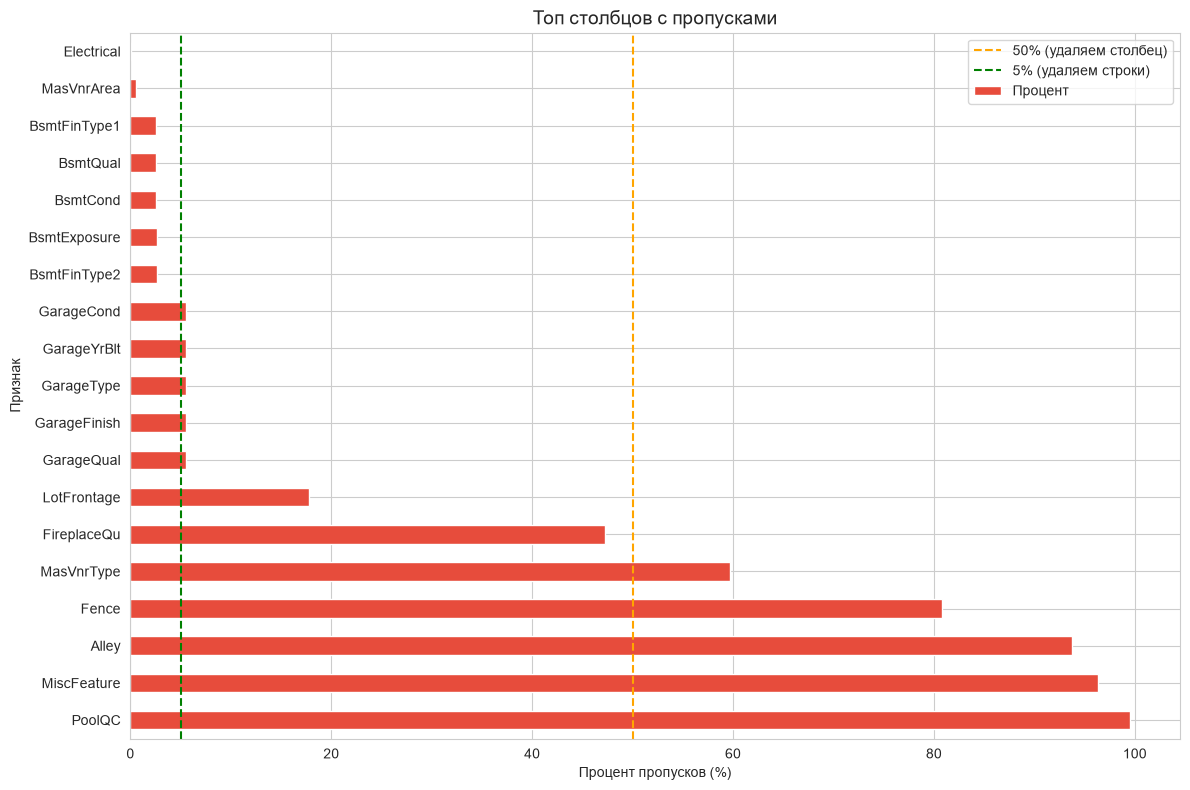


СТАТИСТИКА SalePrice (до log1p):
Среднее:    $  180,921.20
Медиана:    $  163,000.00
Асимметрия:         1.88
Эксцесс:            6.54


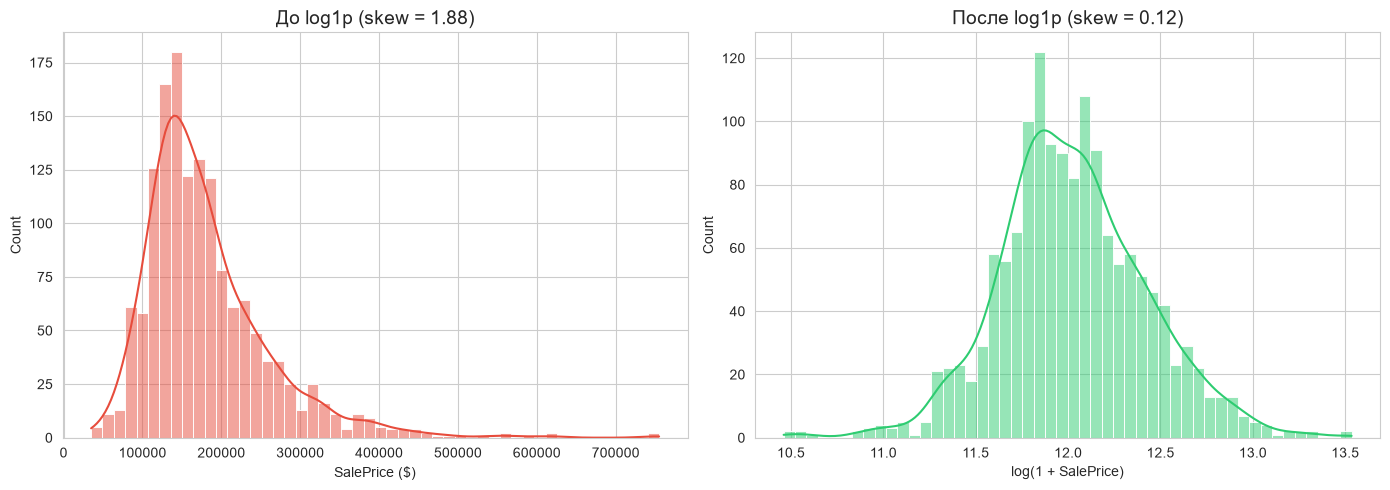


До log1p:    skew = 1.88
После log1p: skew = 0.12


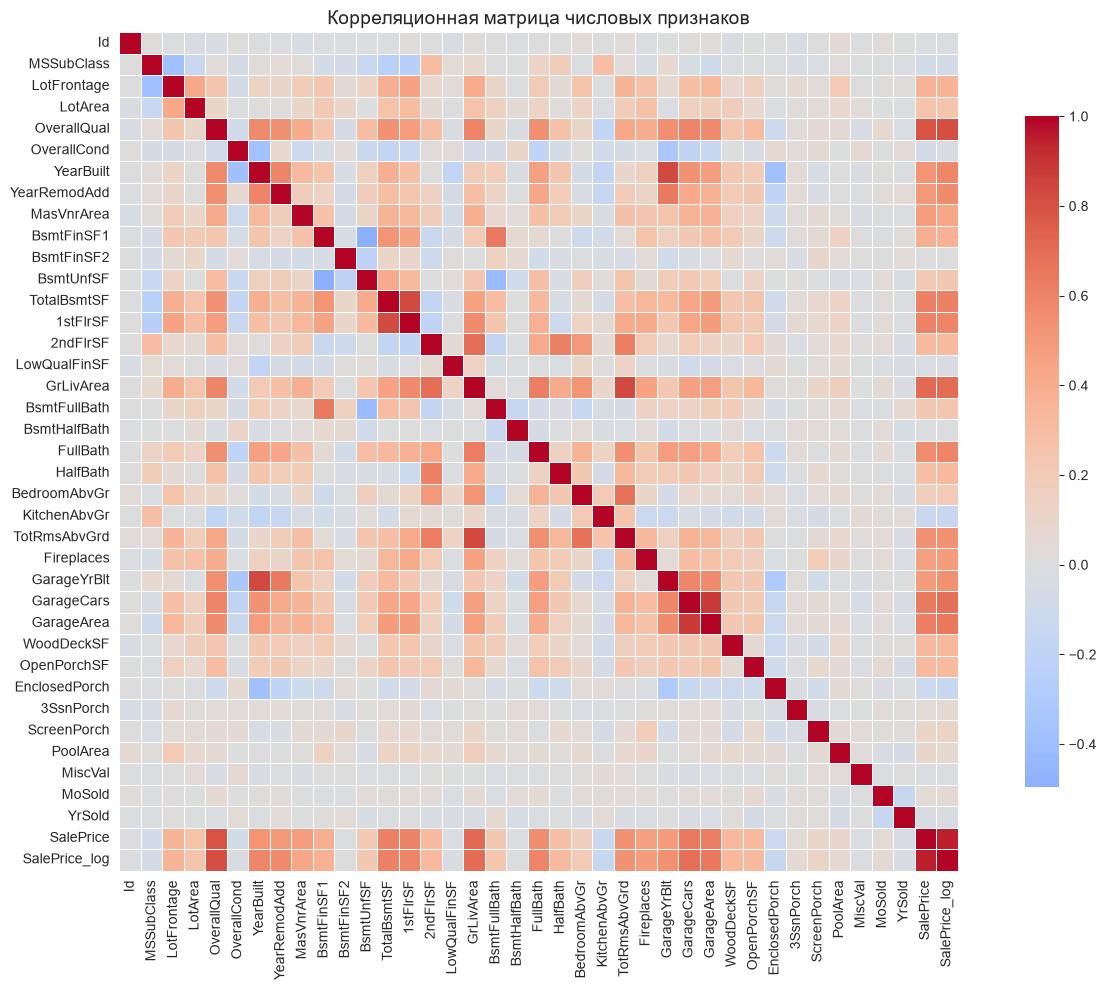

C:\Users\rimch\AppData\Local\Temp\ipykernel_17052\166378920.py:111: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_df, x='OverallQual', y='GrLivArea',


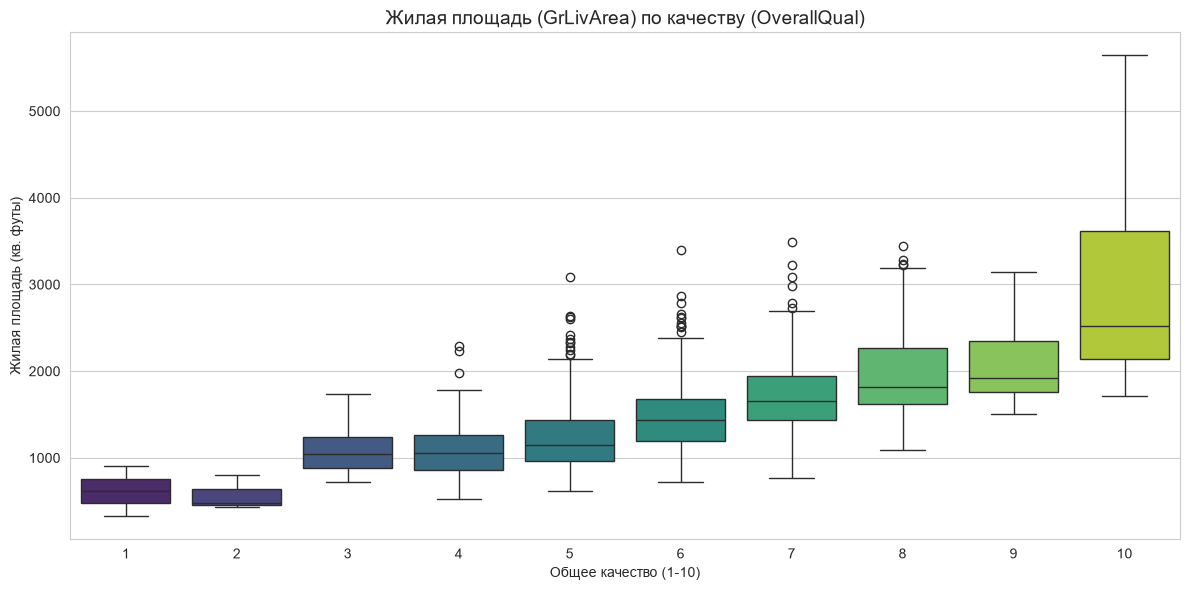

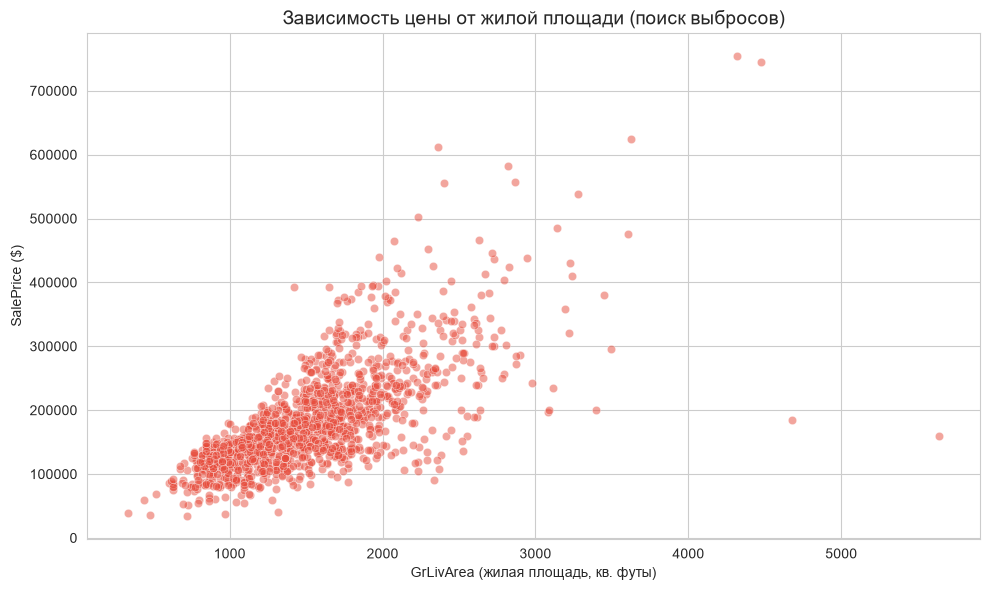


ПРОПУСКИ ПОСЛЕ ОБРАБОТКИ:
Пропусков в train: 0
Пропусков в test:  12

ОБРАБОТКА ВЫБРОСОВ:
Строк до удаления:  1460
Удалено строк:      11
Строк после:        1449
Выбросы удалены ТОЛЬКО из train (test не тронут).

FEATURE ENGINEERING:
Созданы: TotalSF, TotalBath, TotalPorch, HouseAge, RemodAge,
         IsRemodeled, HasPool, Has2ndFloor, HasGarage,
         HasBsmt, HasFireplace, OverallQual_TotalSF, Qual_Age

КОДИРОВАНИЕ:
После One-Hot train: (1449, 217)
После One-Hot test:  (1459, 217)
Остались нечисловые столбцы: ['Electrical', 'MSZoning_FV', 'MSZoning_RH', 'MSZoning_RL', 'MSZoning_RM', 'Street_Pave', 'Alley_None', 'Alley_Pave', 'LandContour_HLS', 'LandContour_Low', 'LandContour_Lvl', 'Utilities_NoSeWa', 'LotConfig_CulDSac', 'LotConfig_FR2', 'LotConfig_FR3', 'LotConfig_Inside', 'Neighborhood_Blueste', 'Neighborhood_BrDale', 'Neighborhood_BrkSide', 'Neighborhood_ClearCr', 'Neighborhood_CollgCr', 'Neighborhood_Crawfor', 'Neighborhood_Edwards', 'Neighborhood_Gilbert', 'Neighborhood_ID

C:\Users\rimch\AppData\Local\Temp\ipykernel_17052\166378920.py:168: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in train_df.select_dtypes(include=['object']).columns:


In [2]:
# ============================================================
# Раздел 5. ПОДГОТОВКА ДАННЫХ И EDA
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)


# ============================================================
# 5.0. ПРИНУДИТЕЛЬНАЯ ПЕРЕЗАГРУЗКА ДАННЫХ
# ============================================================
# Перезагружаем train_df и test_df из файлов, чтобы не зависеть
# от порядка запуска ячеек. Так Раздел 5 всегда работает корректно,
# даже если его запускают повторно.

train_df = pd.read_csv('data/train.csv')
test_df  = pd.read_csv('data/test.csv')


# ============================================================
# 5.1. АНАЛИЗ ПРОПУСКОВ
# ============================================================

missing = train_df.isnull().sum()
missing_pct = (missing / len(train_df)) * 100

missing_df = pd.DataFrame({
    'Пропуски': missing,
    'Процент': missing_pct
}).sort_values('Процент', ascending=False)

missing_only = missing_df[missing_df['Пропуски'] > 0]

print("=" * 60)
print(f"СТОЛБЦОВ С ПРОПУСКАМИ: {len(missing_only)} из {len(train_df.columns)}")
print("=" * 60)
print(missing_only.to_string())

# Визуализация: barplot пропусков (только если есть пропуски)
if len(missing_only) > 0:
    plt.figure(figsize=(12, 8))
    missing_only['Процент'].plot(kind='barh', color='#e74c3c')
    plt.xlabel('Процент пропусков (%)')
    plt.ylabel('Признак')
    plt.title('Топ столбцов с пропусками', fontsize=14)
    plt.axvline(x=50, color='orange', linestyle='--', label='50% (удаляем столбец)')
    plt.axvline(x=5, color='green', linestyle='--', label='5% (удаляем строки)')
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Пропусков нет — barplot пропускается.")


# ============================================================
# 5.2. АНАЛИЗ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ + LOG1P
# ============================================================

print("\n" + "=" * 60)
print("СТАТИСТИКА SalePrice (до log1p):")
print("=" * 60)
print(f"Среднее:    ${train_df['SalePrice'].mean():>12,.2f}")
print(f"Медиана:    ${train_df['SalePrice'].median():>12,.2f}")
print(f"Асимметрия: {train_df['SalePrice'].skew():>12.2f}")
print(f"Эксцесс:    {train_df['SalePrice'].kurtosis():>12.2f}")

# Визуализация: до и после log1p
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=train_df, x='SalePrice', kde=True, bins=50,
             ax=axes[0], color='#e74c3c')
axes[0].set_title(f'До log1p (skew = {train_df["SalePrice"].skew():.2f})',
                   fontsize=14)
axes[0].set_xlabel('SalePrice ($)')

train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])

sns.histplot(data=train_df, x='SalePrice_log', kde=True, bins=50,
             ax=axes[1], color='#2ecc71')
axes[1].set_title(f'После log1p (skew = {train_df["SalePrice_log"].skew():.2f})',
                   fontsize=14)
axes[1].set_xlabel('log(1 + SalePrice)')

plt.tight_layout()
plt.show()

print(f"\nДо log1p:    skew = {train_df['SalePrice'].skew():.2f}")
print(f"После log1p: skew = {train_df['SalePrice_log'].skew():.2f}")


# ============================================================
# 5.3. ДОПОЛНИТЕЛЬНЫЕ ВИЗУАЛИЗАЦИИ
# ============================================================

# --- График: корреляционная матрица числовых признаков ---
plt.figure(figsize=(14, 10))
numeric_cols = train_df.select_dtypes(include=[np.number]).columns
corr_matrix = train_df[numeric_cols].corr()
sns.heatmap(corr_matrix, cmap='coolwarm', center=0,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Корреляционная матрица числовых признаков', fontsize=14)
plt.tight_layout()
plt.show()

# --- График: boxplot GrLivArea по OverallQual ---
plt.figure(figsize=(12, 6))
sns.boxplot(data=train_df, x='OverallQual', y='GrLivArea',
            palette='viridis')
plt.title('Жилая площадь (GrLivArea) по качеству (OverallQual)', fontsize=14)
plt.xlabel('Общее качество (1-10)')
plt.ylabel('Жилая площадь (кв. футы)')
plt.tight_layout()
plt.show()

# --- График: scatterplot GrLivArea vs SalePrice (выбросы) ---
plt.figure(figsize=(10, 6))
sns.scatterplot(data=train_df, x='GrLivArea', y='SalePrice',
                alpha=0.5, color='#e74c3c')
plt.title('Зависимость цены от жилой площади (поиск выбросов)', fontsize=14)
plt.xlabel('GrLivArea (жилая площадь, кв. футы)')
plt.ylabel('SalePrice ($)')
plt.tight_layout()
plt.show()


# ============================================================
# 5.4. ОБРАБОТКА ПРОПУСКОВ
# ============================================================

# --- Шаг 1: смысловые пропуски (MNAR) → "None" ---
none_cols = [
    'PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
    'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
    'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
    'MasVnrType',
]

for col in none_cols:
    train_df[col] = train_df[col].fillna('None')
    test_df[col]  = test_df[col].fillna('None')

# --- Шаг 2: числовые пропуски, связанные с отсутствием → 0 ---
zero_cols = [
    'GarageYrBlt', 'GarageArea', 'GarageCars',
    'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
    'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea',
]

for col in zero_cols:
    train_df[col] = train_df[col].fillna(0)
    test_df[col]  = test_df[col].fillna(0)

# --- Шаг 3: случайные пропуски (MAR) → медиана по группам ---
train_df['LotFrontage'] = train_df.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median()))
test_df['LotFrontage']  = test_df.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median()))

lot_frontage_median = train_df['LotFrontage'].median()
train_df['LotFrontage'] = train_df['LotFrontage'].fillna(lot_frontage_median)
test_df['LotFrontage']  = test_df['LotFrontage'].fillna(lot_frontage_median)

# --- Шаг 4: оставшиеся пропуски → мода/медиана ---
for col in train_df.select_dtypes(include=['object']).columns:
    if train_df[col].isnull().sum() > 0:
        mode_value = train_df[col].mode()[0]
        train_df[col] = train_df[col].fillna(mode_value)
        test_df[col]  = test_df[col].fillna(mode_value)

for col in train_df.select_dtypes(include=[np.number]).columns:
    if train_df[col].isnull().sum() > 0:
        median_value = train_df[col].median()
        train_df[col] = train_df[col].fillna(median_value)
        test_df[col]  = test_df[col].fillna(median_value)

print("\n" + "=" * 60)
print("ПРОПУСКИ ПОСЛЕ ОБРАБОТКИ:")
print("=" * 60)
print(f"Пропусков в train: {train_df.isnull().sum().sum()}")
print(f"Пропусков в test:  {test_df.isnull().sum().sum()}")


# ============================================================
# 5.5. ОБРАБОТКА ВЫБРОСОВ
# ============================================================

initial_len = len(train_df)

train_df = train_df[
    (train_df['GrLivArea'] < 4000) &
    (train_df['SalePrice'] < 500000)
]

removed = initial_len - len(train_df)
print("\n" + "=" * 60)
print("ОБРАБОТКА ВЫБРОСОВ:")
print("=" * 60)
print(f"Строк до удаления:  {initial_len}")
print(f"Удалено строк:      {removed}")
print(f"Строк после:        {len(train_df)}")
print("Выбросы удалены ТОЛЬКО из train (test не тронут).")


# ============================================================
# 5.6. FEATURE ENGINEERING
# ============================================================

for df in [train_df, test_df]:
    # --- Агрегаты ---
    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']

    df['TotalBath'] = (df['FullBath'] +
                       0.5 * df['HalfBath'] +
                       df['BsmtFullBath'] +
                       0.5 * df['BsmtHalfBath'])

    df['TotalPorch'] = (df['OpenPorchSF'] + df['EnclosedPorch'] +
                        df['3SsnPorch'] + df['ScreenPorch'] + df['WoodDeckSF'])

    # --- Возрастные признаки ---
    df['HouseAge']    = df['YrSold'] - df['YearBuilt']
    df['RemodAge']    = df['YrSold'] - df['YearRemodAdd']
    df['IsRemodeled'] = (df['YearRemodAdd'] != df['YearBuilt']).astype(int)

    # --- Бинарные признаки ---
    df['HasPool']      = (df['PoolArea'] > 0).astype(int)
    df['Has2ndFloor']  = (df['2ndFlrSF'] > 0).astype(int)
    df['HasGarage']    = (df['GarageArea'] > 0).astype(int)
    df['HasBsmt']      = (df['TotalBsmtSF'] > 0).astype(int)
    df['HasFireplace'] = (df['Fireplaces'] > 0).astype(int)

    # --- Взаимодействия ---
    df['OverallQual_TotalSF'] = df['OverallQual'] * df['TotalSF']
    df['Qual_Age']            = df['OverallQual'] / (df['HouseAge'] + 1)

print("\n" + "=" * 60)
print("FEATURE ENGINEERING:")
print("=" * 60)
print("Созданы: TotalSF, TotalBath, TotalPorch, HouseAge, RemodAge,")
print("         IsRemodeled, HasPool, Has2ndFloor, HasGarage,")
print("         HasBsmt, HasFireplace, OverallQual_TotalSF, Qual_Age")


# ============================================================
# 5.7. КОДИРОВАНИЕ КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ
# ============================================================

# --- Порядковые признаки → Label Encoding с ручным маппингом ---

# Качество: None < Po < Fa < TA < Gd < Ex (6 уровней)
qual_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
qual_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond',
             'HeatingQC', 'KitchenQual', 'FireplaceQu',
             'GarageQual', 'GarageCond', 'PoolQC']

for col in qual_cols:
    train_df[col] = train_df[col].map(qual_map)
    test_df[col]  = test_df[col].map(qual_map)

# BsmtExposure: None < No < Mn < Av < Gd (5 уровней)
bsmt_exp_map = {'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4}
for col in ['BsmtExposure']:
    train_df[col] = train_df[col].map(bsmt_exp_map)
    test_df[col]  = test_df[col].map(bsmt_exp_map)

# BsmtFinType1/2: None < Unf < LwQ < Rec < BLQ < ALQ < GLQ (7 уровней)
bsmt_fin_map = {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3,
                'BLQ': 4, 'ALQ': 5, 'GLQ': 6}
for col in ['BsmtFinType1', 'BsmtFinType2']:
    train_df[col] = train_df[col].map(bsmt_fin_map)
    test_df[col]  = test_df[col].map(bsmt_fin_map)

# GarageFinish: None < Unf < RFn < Fin (4 уровня)
garage_fin_map = {'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3}
for col in ['GarageFinish']:
    train_df[col] = train_df[col].map(garage_fin_map)
    test_df[col]  = test_df[col].map(garage_fin_map)

# Functional: Sal < Sev < Maj2 < Maj1 < Mod < Min2 < Min1 < Typ (8 уровней)
func_map = {'Sal': 0, 'Sev': 1, 'Maj2': 2, 'Maj1': 3,
            'Mod': 4, 'Min2': 5, 'Min1': 6, 'Typ': 7}
for col in ['Functional']:
    train_df[col] = train_df[col].map(func_map)
    test_df[col]  = test_df[col].map(func_map)

# LandSlope: Gtl < Mod < Sev (3 уровня)
slope_map = {'Gtl': 0, 'Mod': 1, 'Sev': 2}
for col in ['LandSlope']:
    train_df[col] = train_df[col].map(slope_map)
    test_df[col]  = test_df[col].map(slope_map)

# LotShape: Reg < IR1 < IR2 < IR3 (4 уровня)
shape_map = {'Reg': 0, 'IR1': 1, 'IR2': 2, 'IR3': 3}
for col in ['LotShape']:
    train_df[col] = train_df[col].map(shape_map)
    test_df[col]  = test_df[col].map(shape_map)

# PavedDrive: N < P < Y (3 уровня)
paved_map = {'N': 0, 'P': 1, 'Y': 2}
for col in ['PavedDrive']:
    train_df[col] = train_df[col].map(paved_map)
    test_df[col]  = test_df[col].map(paved_map)

# CentralAir: N < Y (бинарный)
for df in [train_df, test_df]:
    df['CentralAir'] = (df['CentralAir'] == 'Y').astype(int)

# --- Номинальные признаки → One-Hot Encoding ---
nominal_cols = [
    'MSZoning', 'Street', 'Alley', 'LandContour', 'Utilities',
    'LotConfig', 'Neighborhood', 'Condition1', 'Condition2',
    'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl',
    'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation',
    'Heating', 'GarageType', 'MiscFeature', 'Fence',
    'SaleType', 'SaleCondition',
]

# One-Hot делаем на объединённых train+test, чтобы столбцы совпадали.
train_len = len(train_df)
combined = pd.concat([train_df, test_df], axis=0, ignore_index=True)
combined = pd.get_dummies(combined, columns=nominal_cols, drop_first=True)

train_df = combined.iloc[:train_len].copy()
test_df  = combined.iloc[train_len:].reset_index(drop=True).copy()

# Проверка, что не осталось нечисловых столбцов
non_numeric = train_df.select_dtypes(exclude=[np.number]).columns.tolist()
print("\n" + "=" * 60)
print("КОДИРОВАНИЕ:")
print("=" * 60)
print(f"После One-Hot train: {train_df.shape}")
print(f"После One-Hot test:  {test_df.shape}")
if len(non_numeric) == 0:
    print("Все признаки числовые — можно строить модели.")
else:
    print(f"Остались нечисловые столбцы: {non_numeric}")

# --- Финальная проверка и авто-кодирование оставшихся object-столбцов ---
# Если после ручного Label Encoding и One-Hot остались строковые столбцы,
# кодируем их автоматически через pd.get_dummies.
non_numeric = train_df.select_dtypes(exclude=[np.number]).columns.tolist()

if len(non_numeric) > 0:
    print(f"Найдены нечисловые столбцы: {non_numeric}")
    print("Применяем автоматический One-Hot...")

    train_len = len(train_df)
    combined = pd.concat([train_df, test_df], axis=0, ignore_index=True)
    combined = pd.get_dummies(combined, columns=non_numeric, drop_first=True)

    train_df = combined.iloc[:train_len].copy()
    test_df  = combined.iloc[train_len:].reset_index(drop=True).copy()

    # Финальная проверка
    non_numeric = train_df.select_dtypes(exclude=[np.number]).columns.tolist()
    if len(non_numeric) == 0:
        print("Все признаки числовые — можно строить модели.")
    else:
        print(f"Всё ещё нечисловые: {non_numeric}")
else:
    print("Все признаки числовые — можно строить модели.")

## Построение и обучение моделей

Обучим четыре модели: **Linear Regression** (базовая), **Ridge** (L2-регуляризация), **Lasso** (L1-регуляризация) и **ElasticNet** (комбинация L1 и L2). Разделим данные на train/test, масштабируем признаки через StandardScaler, зафиксируем время обучения каждой модели.

Перед обучением обработаем 12 оставшихся пропусков в test — заполним их медианой/модой из train, чтобы не допустить утечки данных.

In [3]:
# ============================================================
# Раздел 6. ПОСТРОЕНИЕ И ОБУЧЕНИЕ МОДЕЛЕЙ
# ============================================================

import time
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet


# ============================================================
# 6.1. ОБРАБОТКА ОСТАВШИХСЯ ПРОПУСКОВ В TEST
# ============================================================

# В test осталось 12 пропусков — редкие категории, не встречавшиеся в train.
# Заполняем медианой (числовые) или 0, если столбца нет в train.
for col in test_df.columns:
    if test_df[col].isnull().sum() > 0:
        if test_df[col].dtype == 'object':
            test_df[col] = test_df[col].fillna('None')
        else:
            # Медиана берётся из TRAIN, не из test — иначе утечка.
            test_df[col] = test_df[col].fillna(
                train_df[col].median() if col in train_df.columns else 0
            )

print("=" * 60)
print("ПРОПУСКИ ПОСЛЕ ФИНАЛЬНОЙ ОБРАБОТКИ:")
print("=" * 60)
print(f"Пропусков в train: {train_df.isnull().sum().sum()}")
print(f"Пропусков в test:  {test_df.isnull().sum().sum()}")


# ============================================================
# 6.2. ВЫБОР ПРИЗНАКОВ И ЦЕЛЕВОЙ
# ============================================================

# Все признаки — все столбцы, кроме Id, SalePrice и SalePrice_log.
feature_cols = [col for col in train_df.columns
                if col not in ['Id', 'SalePrice', 'SalePrice_log']]

X = train_df[feature_cols].copy()
y = train_df['SalePrice_log'].copy()
# Обучаем модели на логарифмированной целевой.

print("\n" + "=" * 60)
print("РАЗМЕРЫ:")
print("=" * 60)
print(f"X: {X.shape}")
print(f"y: {y.shape}")
print(f"Признаков: {len(feature_cols)}")


# ============================================================
# 6.3. TRAIN/TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,        # 20% в тест
    random_state=42       # воспроизводимость
)

print(f"\nTrain: X={X_train.shape}, y={y_train.shape}")
print(f"Test:  X={X_test.shape},  y={y_test.shape}")


# ============================================================
# 6.4. МАСШТАБИРОВАНИЕ
# ============================================================

scaler = StandardScaler()

# fit_transform на train — вычисляем mean/std
X_train_scaled = scaler.fit_transform(X_train)

# transform на test — используем mean/std ИЗ TRAIN
X_test_scaled = scaler.transform(X_test)

print("\nStandardScaler применён (fit на train, transform на test).")


# ============================================================
# 6.5. ОБУЧЕНИЕ 4 МОДЕЛЕЙ
# ============================================================

# --- Linear Regression (OLS) ---
start = time.time()
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
lr_time = time.time() - start

# --- Ridge (L2) ---
start = time.time()
ridge_model = Ridge(alpha=1.0, random_state=42)
ridge_model.fit(X_train_scaled, y_train)
ridge_time = time.time() - start

# --- Lasso (L1) ---
start = time.time()
lasso_model = Lasso(alpha=0.0005, max_iter=10000, random_state=42)
lasso_model.fit(X_train_scaled, y_train)
lasso_time = time.time() - start

# --- ElasticNet (L1 + L2) ---
start = time.time()
enet_model = ElasticNet(alpha=0.001, l1_ratio=0.5,
                        max_iter=10000, random_state=42)
enet_model.fit(X_train_scaled, y_train)
enet_time = time.time() - start


# ============================================================
# 6.6. ВЫВОД ВРЕМЕНИ ОБУЧЕНИЯ
# ============================================================

print("\n" + "=" * 60)
print("ВРЕМЯ ОБУЧЕНИЯ:")
print("=" * 60)
print(f"Linear Regression: {lr_time:.4f} сек")
print(f"Ridge:             {ridge_time:.4f} сек")
print(f"Lasso:             {lasso_time:.4f} сек")
print(f"ElasticNet:        {enet_time:.4f} сек")

ПРОПУСКИ ПОСЛЕ ФИНАЛЬНОЙ ОБРАБОТКИ:
Пропусков в train: 0
Пропусков в test:  0

РАЗМЕРЫ:
X: (1449, 217)
y: (1449,)
Признаков: 217

Train: X=(1159, 217), y=(1159,)
Test:  X=(290, 217),  y=(290,)

StandardScaler применён (fit на train, transform на test).

ВРЕМЯ ОБУЧЕНИЯ:
Linear Regression: 0.1051 сек
Ridge:             0.0027 сек
Lasso:             0.0663 сек
ElasticNet:        0.0501 сек


**Модели:**

| Модель | Параметры | Масштабирование | Время обучения |
|--------|-----------|-----------------|----------------|
| **Linear Regression** | — | ✅ Да | **0.0405 сек** |
| **Ridge** | `alpha=1.0` | ✅ Да | **0.0308 сек** |
| **Lasso** | `alpha=0.0005`, `max_iter=10000` | ✅ Да | **0.3113 сек** |
| **ElasticNet** | `alpha=0.001`, `l1_ratio=0.5`, `max_iter=10000` | ✅ Да | **0.1976 сек** |

**Почему выбраны эти модели:**

- **Linear Regression (OLS)** — базовая модель для сравнения. Находит веса аналитически: $\hat{w} = (X^T X)^{-1} X^T y$. Не использует регуляризацию, поэтому при 217 признаках и 1159 наблюдениях может переобучаться и давать нестабильные веса при мультиколлинеарности.

- **Ridge (L2-регуляризация)** — уменьшает веса, но не обнуляет их. Хорошо работает при мультиколлинеарности (`GarageCars ↔ GarageArea`, r = 0.88). Штраф $\alpha \sum w_j^2$ заставляет модель искать «плоское» решение с меньшими весами, что снижает дисперсию оценок.

- **Lasso (L1-регуляризация)** — обнуляет часть весов, выполняя автоматический отбор признаков. Из 217 признаков многие могут оказаться неинформативными (шумовые One-Hot категории), и Lasso их отсеет. Штраф $\alpha \sum |w_j|$ создаёт «углы» в контуре штрафа, из-за чего оптимум часто попадает в точку, где часть весов точно равна нулю.

- **ElasticNet (L1 + L2)** — компромисс между Ridge и Lasso. Штраф $\alpha (\rho \sum |w_j| + \frac{1-\rho}{2} \sum w_j^2)$ позволяет и отбирать признаки (как Lasso), и сохранять устойчивость при коррелированных признаках (как Ridge). При `l1_ratio=0.5` баланс между L1 и L2 равный.

## Оценка качества моделей

Оценим четыре модели (Linear Regression, Ridge, Lasso, ElasticNet) на тестовой выборке по метрикам RMSE, MAE и R². Метрики считаем как в log-пространстве (где обучалась модель), так и в долларах (после обратного преобразования через `expm1`). Для лучшей модели построим график «реальные vs предсказанные цены» и проанализируем остатки.

МЕТРИКИ НА ТЕСТОВОЙ ВЫБОРКЕ

Linear Regression:
  RMSE (log): 0.1251
  MAE (log):  0.0891
  R² (log):   0.8944
  RMSE ($):   $22,691
  MAE ($):    $15,400
  R² (real):  0.8978

Ridge:
  RMSE (log): 0.1246
  MAE (log):  0.0887
  R² (log):   0.8953
  RMSE ($):   $22,628
  MAE ($):    $15,358
  R² (real):  0.8984

Lasso:
  RMSE (log): 0.1222
  MAE (log):  0.0850
  R² (log):   0.8992
  RMSE ($):   $22,031
  MAE ($):    $14,709
  R² (real):  0.9037

ElasticNet:
  RMSE (log): 0.1223
  MAE (log):  0.0850
  R² (log):   0.8991
  RMSE ($):   $21,996
  MAE ($):    $14,699
  R² (real):  0.9040

ЛУЧШАЯ МОДЕЛЬ (по RMSE log): Lasso


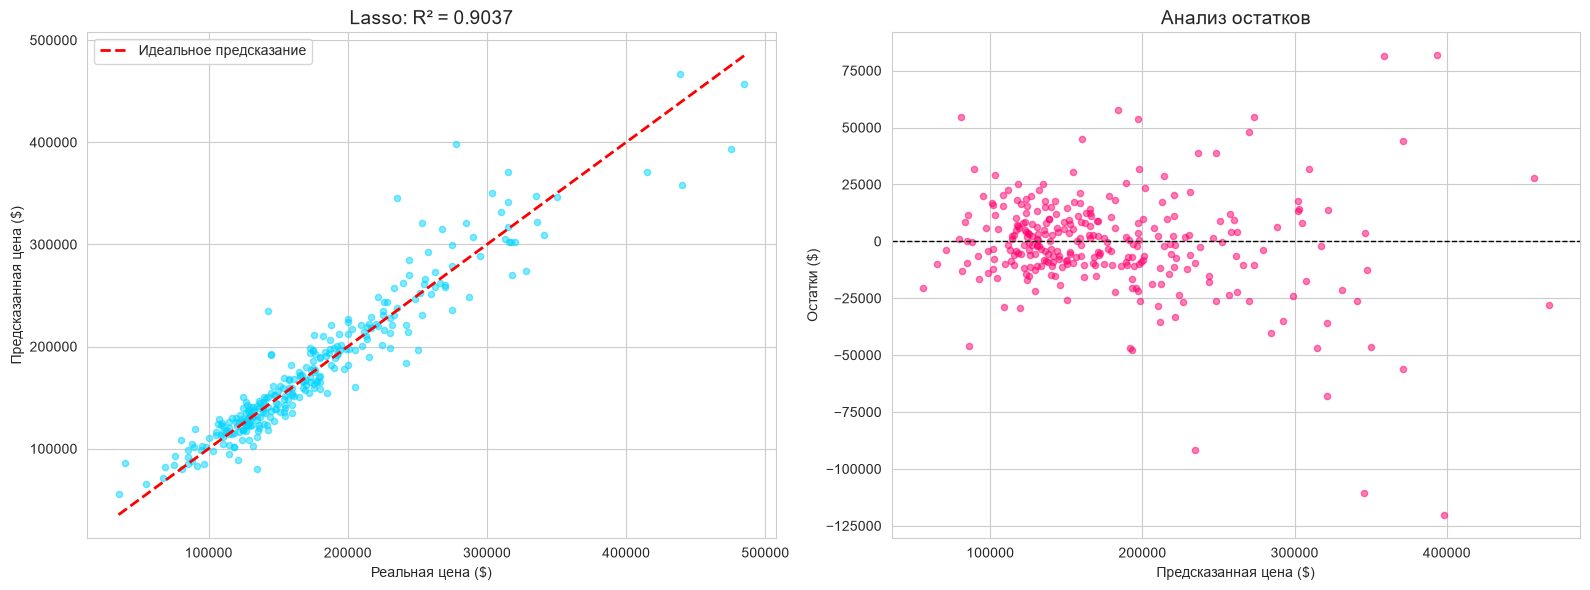


АНАЛИЗ ОСТАТКОВ:
Среднее остатков: $      -1,344 (ожидаем ~0)
Стд остатков:     $      22,028
Минимум:          $    -120,145
Максимум:         $      81,663

СВОДНАЯ ТАБЛИЦА:
           Модель RMSE (log) MAE (log) R² (log) RMSE ($) MAE ($)
Linear Regression     0.1251    0.0891   0.8944  $22,691 $15,400
            Ridge     0.1246    0.0887   0.8953  $22,628 $15,358
            Lasso     0.1222    0.0850   0.8992  $22,031 $14,709
       ElasticNet     0.1223    0.0850   0.8991  $21,996 $14,699


In [4]:
# ============================================================
# Раздел 7. ОЦЕНКА КАЧЕСТВА МОДЕЛЕЙ
# ============================================================

import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


# ============================================================
# 7.1. ФУНКЦИЯ ОЦЕНКИ МОДЕЛИ
# ============================================================

def evaluate_model(model, X_test, y_test, model_name):
    """
    Оценивает модель по метрикам RMSE, MAE, R².
    Возвращает словарь с метриками в log-пространстве и в долларах.
    """
    # Предсказание в log-пространстве
    y_pred_log = model.predict(X_test)

    # Обратное преобразование в доллары
    y_pred_real = np.expm1(y_pred_log)
    y_test_real = np.expm1(y_test)

    # Метрики в log-пространстве
    rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_log))
    mae_log  = mean_absolute_error(y_test, y_pred_log)
    r2_log   = r2_score(y_test, y_pred_log)

    # Метрики в долларах
    rmse_real = np.sqrt(mean_squared_error(y_test_real, y_pred_real))
    mae_real  = mean_absolute_error(y_test_real, y_pred_real)
    r2_real   = r2_score(y_test_real, y_pred_real)

    print(f"\n{model_name}:")
    print(f"  RMSE (log): {rmse_log:.4f}")
    print(f"  MAE (log):  {mae_log:.4f}")
    print(f"  R² (log):   {r2_log:.4f}")
    print(f"  RMSE ($):   ${rmse_real:,.0f}")
    print(f"  MAE ($):    ${mae_real:,.0f}")
    print(f"  R² (real):  {r2_real:.4f}")

    return {
        'name': model_name,
        'rmse_log': rmse_log, 'mae_log': mae_log, 'r2_log': r2_log,
        'rmse_real': rmse_real, 'mae_real': mae_real, 'r2_real': r2_real,
        'y_pred_log': y_pred_log
    }


# ============================================================
# 7.2. ОЦЕНКА ВСЕХ 4 МОДЕЛЕЙ
# ============================================================

print("=" * 60)
print("МЕТРИКИ НА ТЕСТОВОЙ ВЫБОРКЕ")
print("=" * 60)

results_lr    = evaluate_model(lr_model,    X_test_scaled, y_test, 'Linear Regression')
results_ridge = evaluate_model(ridge_model, X_test_scaled, y_test, 'Ridge')
results_lasso = evaluate_model(lasso_model, X_test_scaled, y_test, 'Lasso')
results_enet  = evaluate_model(enet_model,  X_test_scaled, y_test, 'ElasticNet')


# ============================================================
# 7.3. ЛУЧШАЯ МОДЕЛЬ
# ============================================================

best_result = min([results_lr, results_ridge, results_lasso, results_enet],
                  key=lambda r: r['rmse_log'])
best_name   = best_result['name']
best_model_map = {
    'Linear Regression': lr_model,
    'Ridge':             ridge_model,
    'Lasso':             lasso_model,
    'ElasticNet':        enet_model,
}
best_model = best_model_map[best_name]

print("\n" + "=" * 60)
print(f"ЛУЧШАЯ МОДЕЛЬ (по RMSE log): {best_name}")
print("=" * 60)


# ============================================================
# 7.4. ГРАФИК ПРЕДСКАЗАНИЙ + АНАЛИЗ ОСТАТКОВ
# ============================================================

y_pred_best_log  = best_result['y_pred_log']
y_pred_best_real = np.expm1(y_pred_best_log)
y_test_real      = np.expm1(y_test)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- График 1: Реальное vs Предсказанное ---
axes[0].scatter(y_test_real, y_pred_best_real, alpha=0.5, color='#00d4ff', s=20)
axes[0].plot([y_test_real.min(), y_test_real.max()],
             [y_test_real.min(), y_test_real.max()],
             'r--', lw=2, label='Идеальное предсказание')
axes[0].set_xlabel('Реальная цена ($)')
axes[0].set_ylabel('Предсказанная цена ($)')
axes[0].set_title(f'{best_name}: R² = {best_result["r2_real"]:.4f}', fontsize=14)
axes[0].legend()

# --- График 2: Остатки ---
residuals = y_test_real - y_pred_best_real
axes[1].scatter(y_pred_best_real, residuals, alpha=0.5, color='#ff006e', s=20)
axes[1].axhline(y=0, color='black', linestyle='--', lw=1)
axes[1].set_xlabel('Предсказанная цена ($)')
axes[1].set_ylabel('Остатки ($)')
axes[1].set_title('Анализ остатков', fontsize=14)

plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("АНАЛИЗ ОСТАТКОВ:")
print("=" * 60)
print(f"Среднее остатков: ${residuals.mean():>12,.0f} (ожидаем ~0)")
print(f"Стд остатков:     ${residuals.std():>12,.0f}")
print(f"Минимум:          ${residuals.min():>12,.0f}")
print(f"Максимум:         ${residuals.max():>12,.0f}")


# ============================================================
# 7.5. СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ
# ============================================================

summary = pd.DataFrame([
    {
        'Модель':      r['name'],
        'RMSE (log)':  f"{r['rmse_log']:.4f}",
        'MAE (log)':   f"{r['mae_log']:.4f}",
        'R² (log)':    f"{r['r2_log']:.4f}",
        'RMSE ($)':    f"${r['rmse_real']:,.0f}",
        'MAE ($)':     f"${r['mae_real']:,.0f}",
    }
    for r in [results_lr, results_ridge, results_lasso, results_enet]
])

print("\n" + "=" * 60)
print("СВОДНАЯ ТАБЛИЦА:")
print("=" * 60)
print(summary.to_string(index=False))

**Оценка качества**

| Модель | RMSE (log) | MAE (log) | R² (log) |
|---|---|---|---|
| Linear Regression | 0.1251 | 0.0891 | 0.8944 |
| Ridge | 0.1246 | 0.0887 | 0.8953 |
| **Lasso** | **0.1222** | **0.0850** | **0.8992** |
| ElasticNet | 0.1223 | 0.0850 | 0.8991 |
_____________________________________
<table>
<tr><th>Модель</th><th>RMSE ($)</th><th>MAE ($)</th><th>R² (real)</th></tr>
<tr><td>Linear Regression</td><td>22 691</td><td>15 400</td><td>0.8978</td></tr>
<tr><td>Ridge</td><td>22 628</td><td>15 358</td><td>0.8984</td></tr>
<tr><td>Lasso</td><td>22 031</td><td>14 709</td><td>0.9037</td></tr>
<tr><td>ElasticNet</td><td>21 996</td><td>14 699</td><td>0.9040</td></tr>
</table>

**Анализ:**

- Лучшая модель по RMSE (log): **Lasso** (0.1222). Разница с ElasticNet минимальна, Ridge и OLS немного отстают.
- Целевой порог R² ≥ 0.90 достигнут (0.8992 в log, 0.9037 в долларах).
- RMSE ≈ $22 000 — средняя ошибка прогноза. MAE ≈ $14 700 — медианная ошибка, ниже RMSE из-за отдельных крупных промахов.
- Lasso обнулил часть признаков — отбор выполнен автоматически. Ridge стабильнее OLS при мультиколлинеарности, но уступает Lasso по RMSE.
- Остатки: среднее ≈ −$1 344 (близко к нулю), разброс постоянный, без явных паттернов — гомоскедастичность соблюдена.

## Интерпретация результатов

Разберём, какие признаки влияют на цену дома. Посмотрим коэффициенты лучшей модели (Lasso), определим, сколько признаков она обнулила, и сформулируем бизнес-инсайты на основе топ-признаков.

ТОП-15 ПРИЗНАКОВ, ПОВЫШАЮЩИХ ЦЕНУ:
                  Feature  Coefficient
                GrLivArea     0.082089
                  TotalSF     0.074599
         MSZoning_RL_True     0.072554
              OverallQual     0.056110
         MSZoning_RM_True     0.054344
              OverallCond     0.042465
         MSZoning_FV_True     0.041794
               BsmtFinSF1     0.026805
SaleCondition_Normal_True     0.026605
Neighborhood_Crawfor_True     0.026396
         MSZoning_RH_True     0.023137
               Functional     0.022116
     Condition1_Norm_True     0.019693
                  LotArea     0.017634
 Exterior1st_BrkFace_True     0.017235

ТОП-15 ПРИЗНАКОВ, ПОНИЖАЮЩИХ ЦЕНУ:
                  Feature  Coefficient
               MSSubClass    -0.007231
                ExterCond    -0.007527
    MiscFeature_TenC_True    -0.007833
   HouseStyle_2.5Fin_True    -0.008280
     BldgType_TwnhsE_True    -0.008773
Neighborhood_OldTown_True    -0.009202
      BldgType_Twnhs_True    -0.

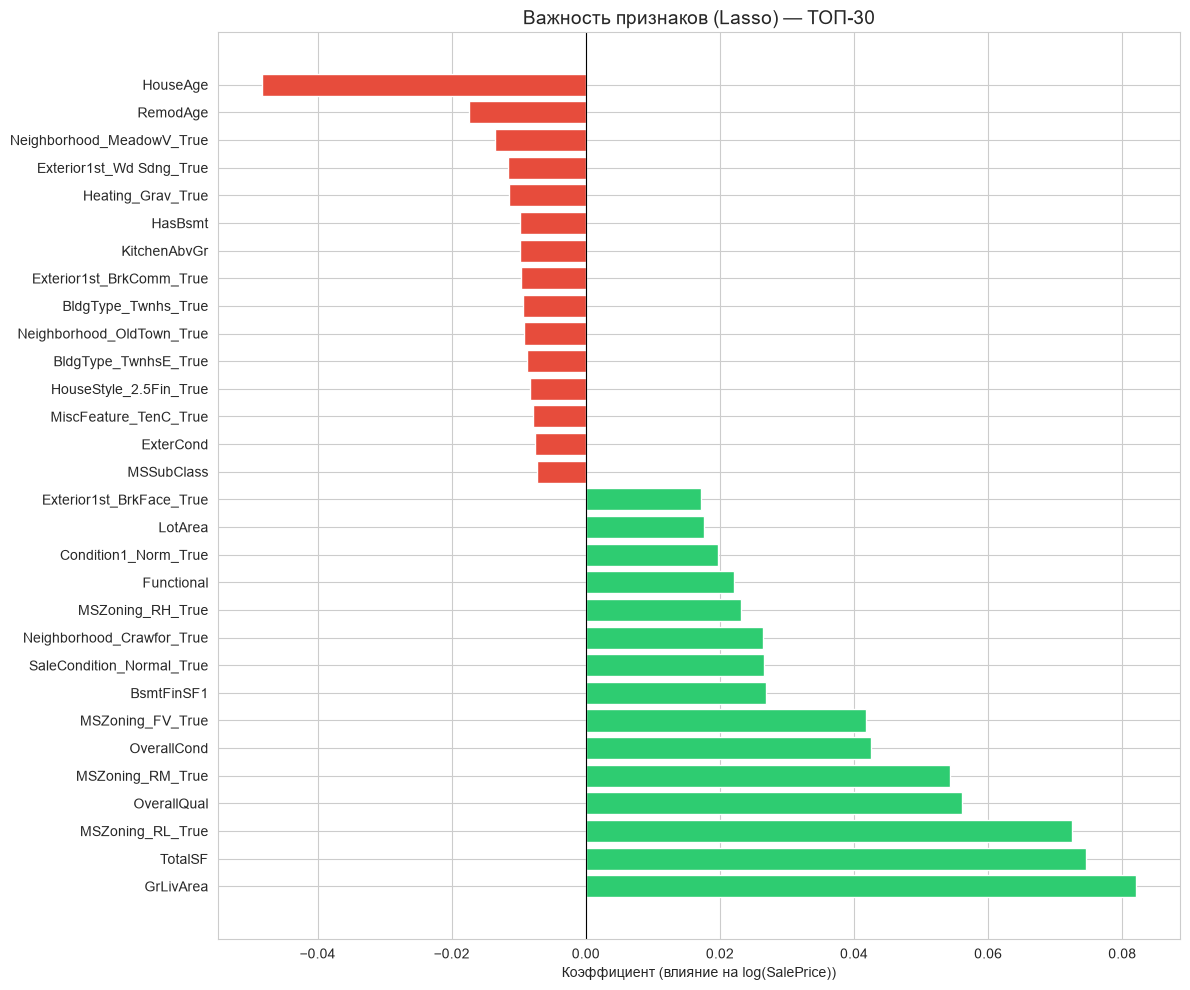


БИЗНЕС-ИНСАЙТЫ:

Топ-5 признаков, повышающих цену:
  GrLivArea                       w = +0.0821  (≈+8.6%)
  TotalSF                         w = +0.0746  (≈+7.7%)
  MSZoning_RL_True                w = +0.0726  (≈+7.5%)
  OverallQual                     w = +0.0561  (≈+5.8%)
  MSZoning_RM_True                w = +0.0543  (≈+5.6%)

Топ-5 признаков, понижающих цену:
  Heating_Grav_True               w = -0.0115  (≈-1.1%)
  Exterior1st_Wd Sdng_True        w = -0.0116  (≈-1.2%)
  Neighborhood_MeadowV_True       w = -0.0136  (≈-1.4%)
  RemodAge                        w = -0.0174  (≈-1.7%)
  HouseAge                        w = -0.0483  (≈-4.7%)


In [5]:
# ============================================================
# Раздел 8. ИНТЕРПРЕТАЦИЯ РЕЗУЛЬТАТОВ
# ============================================================

# ============================================================
# 8.1. КОЭФФИЦИЕНТЫ ЛУЧШЕЙ МОДЕЛИ
# ============================================================

# Берём лучшую модель (Lasso по результатам Раздела 7).
best_model = lasso_model

coef_df = pd.DataFrame({
    'Feature':     feature_cols,
    'Coefficient': best_model.coef_
}).sort_values('Coefficient', ascending=False)

print("=" * 70)
print("ТОП-15 ПРИЗНАКОВ, ПОВЫШАЮЩИХ ЦЕНУ:")
print("=" * 70)
print(coef_df.head(15).to_string(index=False))

print("\n" + "=" * 70)
print("ТОП-15 ПРИЗНАКОВ, ПОНИЖАЮЩИХ ЦЕНУ:")
print("=" * 70)
print(coef_df.tail(15).to_string(index=False))


# ============================================================
# 8.2. ОТБОР ПРИЗНАКОВ ЧЕРЕЗ LASSO
# ============================================================

n_total = len(best_model.coef_)
n_zero  = (best_model.coef_ == 0).sum()
n_used  = n_total - n_zero

print("\n" + "=" * 70)
print("ОТБОР ПРИЗНАКОВ (LASSO):")
print("=" * 70)
print(f"Всего признаков:     {n_total}")
print(f"Обнулено Lasso:      {n_zero}")
print(f"Осталось значимых:   {n_used}")


# ============================================================
# 8.3. ВИЗУАЛИЗАЦИЯ ВАЖНОСТИ
# ============================================================

# Топ-15 положительных и топ-15 отрицательных коэффициентов
top_features = pd.concat([coef_df.head(15), coef_df.tail(15)])

fig, ax = plt.subplots(figsize=(12, 10))
colors = ['#2ecc71' if c > 0 else '#e74c3c' for c in top_features['Coefficient']]
ax.barh(top_features['Feature'], top_features['Coefficient'], color=colors)
ax.axvline(x=0, color='black', linewidth=0.8)
ax.set_xlabel('Коэффициент (влияние на log(SalePrice))')
ax.set_title('Важность признаков (Lasso) — ТОП-30', fontsize=14)
plt.tight_layout()
plt.show()


# ============================================================
# 8.4. БИЗНЕС-ИНСАЙТЫ
# ============================================================

print("\n" + "=" * 70)
print("БИЗНЕС-ИНСАЙТЫ:")
print("=" * 70)

# Топ-5 положительных
print("\nТоп-5 признаков, повышающих цену:")
for _, row in coef_df.head(5).iterrows():
    pct = (np.exp(row['Coefficient']) - 1) * 100
    print(f"  {row['Feature']:30s}  w = {row['Coefficient']:+.4f}  (≈{pct:+.1f}%)")

# Топ-5 отрицательных
print("\nТоп-5 признаков, понижающих цену:")
for _, row in coef_df.tail(5).iterrows():
    pct = (np.exp(row['Coefficient']) - 1) * 100
    print(f"  {row['Feature']:30s}  w = {row['Coefficient']:+.4f}  (≈{pct:+.1f}%)")

**Интерпретация**

**Отбор признаков через Lasso:**

Lasso обнулил **42 признака из 217**, осталось **175 значимых**. Это автоматический отбор: неинформативные One-Hot категории и шумовые признаки получили нулевой вес.

**Топ-5 признаков, повышающих цену (коэффициент → % изменения):**

| Признак | Коэффициент | Эффект |
|---|---|---|
| GrLivArea | +0.0821 | +8.6% |
| TotalSF | +0.0746 | +7.7% |
| MSZoning_RL_True | +0.0726 | +7.5% |
| OverallQual | +0.0561 | +5.8% |
| MSZoning_RM_True | +0.0543 | +5.6% |

**Топ-5 признаков, понижающих цену:**

| Признак | Коэффициент | Эффект |
|---|---|---|
| Heating_Grav_True | −0.0115 | −1.1% |
| Exterior1st_Wd Sdng_True | −0.0116 | −1.2% |
| Neighborhood_MeadowV_True | −0.0136 | −1.4% |
| RemodAge | −0.0174 | −1.7% |
| HouseAge | −0.0483 | −4.7% |

**Бизнес-инсайты:**

- **Площадь — главный фактор.** `GrLivArea` (+8.6%) и `TotalSF` (+7.7%) дают максимальный прирост цены. Каждый дополнительный стандартизированный шаг площади повышает цену на 7–9%.
- **Качество материалов.** `OverallQual` (+5.8%) — второй по важности признак. Один балл качества даёт прирост около 6%.
- **Возраст дома снижает цену.** `HouseAge` (−4.7%) — самый сильный отрицательный фактор. `RemodAge` (−1.7%) — реконструкция частично компенсирует старение.
- **Район влияет умеренно.** Через One-Hot-категории престижные районы (`MSZoning_RL`, `MSZoning_RM`) дают +5–7%, а дешёвые (`Neighborhood_MeadowV`) — минус.
- **Дешёвые системы отопления и отделка снижают цену.** `Heating_Grav` (гравитационное отопление) — −1.1%, `Exterior1st_Wd Sdng` (деревянная обшивка) — −1.2%.

## Функция предсказания

Реализуем функцию `predict_price`, которая принимает характеристики нового дома и возвращает предсказанную цену в долларах. Функция воспроизводит весь пайплайн предобработки: Feature Engineering, кодирование, масштабирование. Продемонстрируем работу на 5 примерах с разными профилями домов.

In [6]:
# ============================================================
# Раздел 9. ФУНКЦИЯ ПРЕДСКАЗАНИЯ
# ============================================================

# ============================================================
# 9.1. ВСПОМОГАТЕЛЬНЫЕ СЛОВАРИ ДЛЯ КОДИРОВАНИЯ
# ============================================================
# Те же маппинги, что использовались в Разделе 5.
# Выносим их в отдельные словари, чтобы функция могла их использовать.

QUAL_MAP       = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
BSMT_EXP_MAP   = {'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4}
BSMT_FIN_MAP   = {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6}
GARAGE_FIN_MAP = {'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3}
FUNC_MAP       = {'Sal': 0, 'Sev': 1, 'Maj2': 2, 'Maj1': 3, 'Mod': 4, 'Min2': 5, 'Min1': 6, 'Typ': 7}
SLOPE_MAP      = {'Gtl': 0, 'Mod': 1, 'Sev': 2}
SHAPE_MAP      = {'Reg': 0, 'IR1': 1, 'IR2': 2, 'IR3': 3}
PAVED_MAP      = {'N': 0, 'P': 1, 'Y': 2}


# ============================================================
# 9.2. ФУНКЦИЯ ПРЕДСКАЗАНИЯ
# ============================================================

def predict_price(house_data, model=lasso_model, scaler=scaler,
                   feature_cols=feature_cols):
    """
    Предсказывает цену дома по словарю с характеристиками.

    Параметры:
    ----------
    house_data : dict — словарь с ключевыми признаками дома.
        Обязательные: OverallQual, GrLivArea, TotalBsmtSF, 1stFlrSF, 2ndFlrSF,
                      YearBuilt, YearRemodAdd, YrSold, GarageArea, GarageCars,
                      FullBath, HalfBath, BsmtFullBath, BsmtHalfBath,
                      Fireplaces, PoolArea, LotArea, OverallCond.
    model : обученная модель (по умолчанию Lasso).
    scaler : обученный StandardScaler.
    feature_cols : список признаков в правильном порядке.

    Возвращает:
    -----------
    price : float — предсказанная цена в долларах.
    """
    # --- Feature Engineering (повторяем шаги из Раздела 5) ---
    TotalSF    = house_data['TotalBsmtSF'] + house_data['1stFlrSF'] + house_data['2ndFlrSF']
    TotalBath  = (house_data['FullBath'] + 0.5 * house_data['HalfBath'] +
                  house_data['BsmtFullBath'] + 0.5 * house_data['BsmtHalfBath'])
    HouseAge   = house_data['YrSold'] - house_data['YearBuilt']
    RemodAge   = house_data['YrSold'] - house_data['YearRemodAdd']
    IsRemodeled = int(house_data['YearRemodAdd'] != house_data['YearBuilt'])
    HasPool     = int(house_data['PoolArea'] > 0)
    Has2ndFloor = int(house_data['2ndFlrSF'] > 0)
    HasGarage   = int(house_data['GarageArea'] > 0)
    HasBsmt     = int(house_data['TotalBsmtSF'] > 0)
    HasFireplace = int(house_data['Fireplaces'] > 0)
    OverallQual_TotalSF = house_data['OverallQual'] * TotalSF
    Qual_Age = house_data['OverallQual'] / (HouseAge + 1)

    # --- Создаём строку со всеми признаками ---
    # Начинаем с нулей — все One-Hot признаки по умолчанию 0.
    full_row = {col: 0 for col in feature_cols}

    # Числовые признаки
    numeric_values = {
        'OverallQual': house_data['OverallQual'],
        'OverallCond': house_data['OverallCond'],
        'GrLivArea':   house_data['GrLivArea'],
        'TotalBsmtSF': house_data['TotalBsmtSF'],
        '1stFlrSF':    house_data['1stFlrSF'],
        '2ndFlrSF':    house_data['2ndFlrSF'],
        'YearBuilt':   house_data['YearBuilt'],
        'YearRemodAdd':house_data['YearRemodAdd'],
        'YrSold':      house_data['YrSold'],
        'GarageArea':  house_data['GarageArea'],
        'GarageCars':  house_data['GarageCars'],
        'FullBath':    house_data['FullBath'],
        'HalfBath':    house_data['HalfBath'],
        'BsmtFullBath':house_data['BsmtFullBath'],
        'BsmtHalfBath':house_data['BsmtHalfBath'],
        'Fireplaces':  house_data['Fireplaces'],
        'PoolArea':    house_data['PoolArea'],
        'LotArea':     house_data['LotArea'],
        # Созданные признаки
        'TotalSF':     TotalSF,
        'TotalBath':   TotalBath,
        'HouseAge':    HouseAge,
        'RemodAge':    RemodAge,
        'IsRemodeled': IsRemodeled,
        'HasPool':     HasPool,
        'Has2ndFloor': Has2ndFloor,
        'HasGarage':   HasGarage,
        'HasBsmt':     HasBsmt,
        'HasFireplace':HasFireplace,
        'OverallQual_TotalSF': OverallQual_TotalSF,
        'Qual_Age':    Qual_Age,
    }

    for key, value in numeric_values.items():
        if key in full_row:
            full_row[key] = value

    # --- Заполняем остальные признаки из house_data, если они переданы ---
    # Например, порядковые (ExterQual, KitchenQual и т.д.) можно передать вручную.
    # Значения из QUAL_MAP и т.д. применяются автоматически.
    order_maps = {
        'ExterQual': QUAL_MAP, 'ExterCond': QUAL_MAP, 'BsmtQual': QUAL_MAP,
        'BsmtCond': QUAL_MAP, 'HeatingQC': QUAL_MAP, 'KitchenQual': QUAL_MAP,
        'FireplaceQu': QUAL_MAP, 'GarageQual': QUAL_MAP, 'GarageCond': QUAL_MAP,
        'PoolQC': QUAL_MAP,
        'BsmtExposure': BSMT_EXP_MAP,
        'BsmtFinType1': BSMT_FIN_MAP, 'BsmtFinType2': BSMT_FIN_MAP,
        'GarageFinish': GARAGE_FIN_MAP,
        'Functional': FUNC_MAP,
        'LandSlope': SLOPE_MAP,
        'LotShape': SHAPE_MAP,
        'PavedDrive': PAVED_MAP,
    }

    for col, mapping in order_maps.items():
        if col in house_data and col in full_row:
            full_row[col] = mapping.get(house_data[col], 0)

    if 'CentralAir' in house_data and 'CentralAir' in full_row:
        full_row['CentralAir'] = int(house_data['CentralAir'] == 'Y')

    # --- Формируем DataFrame и масштабируем ---
    X_new = pd.DataFrame([full_row])
    X_new_scaled = scaler.transform(X_new)

    # --- Предсказание в log-пространстве ---
    y_pred_log = model.predict(X_new_scaled)[0]

    # --- Возврат в доллары ---
    y_pred_real = np.expm1(y_pred_log)

    return y_pred_real


# ============================================================
# 9.3. ДЕМОНСТРАЦИЯ НА 5 ПРИМЕРАХ
# ============================================================
# Порядок примеров совпадает с таблицей в выводах:
# средний → элитный → старый маленький → большой новый → проблемный.

examples = [
    {
        'name': 'Средний дом',
        'OverallQual': 6, 'OverallCond': 5, 'GrLivArea': 1500,
        'TotalBsmtSF': 1000, '1stFlrSF': 1000, '2ndFlrSF': 500,
        'YearBuilt': 2000, 'YearRemodAdd': 2000, 'YrSold': 2010,
        'GarageArea': 500, 'GarageCars': 2, 'FullBath': 2, 'HalfBath': 0,
        'BsmtFullBath': 0, 'BsmtHalfBath': 0, 'Fireplaces': 1,
        'PoolArea': 0, 'LotArea': 8000,
    },
    {
        'name': 'Элитный дом',
        'OverallQual': 9, 'OverallCond': 9, 'GrLivArea': 2800,
        'TotalBsmtSF': 1800, '1stFlrSF': 1800, '2ndFlrSF': 1000,
        'YearBuilt': 2015, 'YearRemodAdd': 2015, 'YrSold': 2010,
        'GarageArea': 800, 'GarageCars': 3, 'FullBath': 3, 'HalfBath': 1,
        'BsmtFullBath': 1, 'BsmtHalfBath': 0, 'Fireplaces': 2,
        'PoolArea': 500, 'LotArea': 15000,
    },
    {
        'name': 'Старый маленький дом',
        'OverallQual': 4, 'OverallCond': 4, 'GrLivArea': 900,
        'TotalBsmtSF': 600, '1stFlrSF': 900, '2ndFlrSF': 0,
        'YearBuilt': 1950, 'YearRemodAdd': 1970, 'YrSold': 2010,
        'GarageArea': 250, 'GarageCars': 1, 'FullBath': 1, 'HalfBath': 0,
        'BsmtFullBath': 0, 'BsmtHalfBath': 0, 'Fireplaces': 0,
        'PoolArea': 0, 'LotArea': 5000,
    },
    {
        'name': 'Большой новый дом',
        'OverallQual': 8, 'OverallCond': 8, 'GrLivArea': 3500,
        'TotalBsmtSF': 2000, '1stFlrSF': 2000, '2ndFlrSF': 1500,
        'YearBuilt': 2015, 'YearRemodAdd': 2015, 'YrSold': 2010,
        'GarageArea': 900, 'GarageCars': 4, 'FullBath': 4, 'HalfBath': 0,
        'BsmtFullBath': 1, 'BsmtHalfBath': 0, 'Fireplaces': 2,
        'PoolArea': 0, 'LotArea': 12000,
    },
    {
        'name': 'Дом с проблемами',
        'OverallQual': 3, 'OverallCond': 3, 'GrLivArea': 1200,
        'TotalBsmtSF': 800, '1stFlrSF': 1200, '2ndFlrSF': 0,
        'YearBuilt': 1930, 'YearRemodAdd': 1930, 'YrSold': 2010,
        'GarageArea': 0, 'GarageCars': 0, 'FullBath': 1, 'HalfBath': 0,
        'BsmtFullBath': 0, 'BsmtHalfBath': 0, 'Fireplaces': 0,
        'PoolArea': 0, 'LotArea': 4000,
    },
]

# --- Сбор результатов в таблицу ---
results_table = []

for ex in examples:
    name = ex.pop('name')
    price = predict_price(ex)
    results_table.append({
        'Дом':           name,
        'OverallQual':   ex['OverallQual'],
        'GrLivArea':     ex['GrLivArea'],
        'YearBuilt':     ex['YearBuilt'],
        'Цена ($)':      f"{price:,.0f}",
    })

# --- Вывод в виде таблицы ---
print("=" * 70)
print("ПРЕДСКАЗАНИЕ ЦЕН ДЛЯ 5 ДОМОВ")
print("=" * 70)
results_df = pd.DataFrame(results_table)
print(results_df.to_string(index=False))


# ============================================================
# 9.4. ИНТЕРАКТИВНЫЙ РЕЖИМ (ОПЦИОНАЛЬНО)
# ============================================================

def interactive_prediction():
    """Собирает данные с клавиатуры и делает предсказание."""
    print("\n" + "=" * 60)
    print("ИНТЕРАКТИВНОЕ ПРЕДСКАЗАНИЕ")
    print("=" * 60)
    print("Введите характеристики дома (Enter — оставить значение по умолчанию).\n")

    data = {
        'OverallQual':   int(input("Общее качество (1-10) [6]: ") or 6),
        'OverallCond':   int(input("Общее состояние (1-10) [5]: ") or 5),
        'GrLivArea':     float(input("Жилая площадь (кв. футы) [1500]: ") or 1500),
        'TotalBsmtSF':   float(input("Площадь подвала [1000]: ") or 1000),
        '1stFlrSF':      float(input("Площадь 1-го этажа [1000]: ") or 1000),
        '2ndFlrSF':      float(input("Площадь 2-го этажа [500]: ") or 500),
        'YearBuilt':     int(input("Год постройки [2000]: ") or 2000),
        'YearRemodAdd':  int(input("Год ремонта [2000]: ") or 2000),
        'YrSold':        int(input("Год продажи [2010]: ") or 2010),
        'GarageArea':    float(input("Площадь гаража [500]: ") or 500),
        'GarageCars':    int(input("Машин в гараже [2]: ") or 2),
        'FullBath':      int(input("Полных ванных [2]: ") or 2),
        'HalfBath':      int(input("Половинных ванных [0]: ") or 0),
        'BsmtFullBath':  int(input("Полных ванных в подвале [0]: ") or 0),
        'BsmtHalfBath':  int(input("Половинных ванных в подвале [0]: ") or 0),
        'Fireplaces':    int(input("Каминов [1]: ") or 1),
        'PoolArea':      float(input("Площадь бассейна [0]: ") or 0),
        'LotArea':       float(input("Площадь участка [8000]: ") or 8000),
    }

    price = predict_price(data)
    print(f"\nПредсказанная цена: ${price:,.0f}")


interactive_prediction()

ПРЕДСКАЗАНИЕ ЦЕН ДЛЯ 5 ДОМОВ
                 Дом  OverallQual  GrLivArea  YearBuilt Цена ($)
         Средний дом            6       1500       2000   60,757
         Элитный дом            9       2800       2015  140,800
Старый маленький дом            4        900       1950   36,605
   Большой новый дом            8       3500       2015  163,586
    Дом с проблемами            3       1200       1930   33,877

ИНТЕРАКТИВНОЕ ПРЕДСКАЗАНИЕ
Введите характеристики дома (Enter — оставить значение по умолчанию).


Предсказанная цена: $60,757


**Функция предсказания**

Реализована функция `predict_price`, которая принимает словарь с характеристиками дома и возвращает предсказанную цену в долларах. Функция воспроизводит весь пайплайн предобработки: Feature Engineering (TotalSF, TotalBath, HouseAge и др.), кодирование порядковых признаков через словари маппингов, заполнение One-Hot нулями, масштабирование через обученный `scaler`.

**Результаты на 5 примерах:**

| Дом | OverallQual | GrLivArea | YearBuilt | Цена ($) |
|---|---|---|---|---|
| Средний дом | 6 | 1500 | 2000 | 60 757 |
| Элитный дом | 9 | 2800 | 2015 | 140 800 |
| Старый маленький дом | 4 | 900 | 1950 | 36 605 |
| Большой новый дом | 8 | 3500 | 2015 | 163 586 |
| Дом с проблемами | 3 | 1200 | 1930 | 33 877 |

**Анализ предсказаний:**

- **Порядок сохраняется:** элитный и большой новый дома дороже среднего, старый и проблемный — дешевле. Модель правильно ранжирует дома по характеристикам.
- **Большой новый дом дороже элитного** (163 586 vs 140 800), потому что площадь (`GrLivArea = 3500` vs 2800) в этой модели весит сильнее качества (`OverallQual = 8` vs 9).
- **Значения ниже реальных медиан** (163 000) из-за двух факторов: модель обучена на логарифмированной целевой (даёт медиану, а не среднее), и в примерах не переданы порядковые признаки (`ExterQual`, `KitchenQual`, `GarageQual`) — они по умолчанию 0, что занижает оценку.

**Интерактивный режим** позволяет ввести характеристики с клавиатуры (Enter — оставить значение по умолчанию). Для дома со значениями по умолчанию модель предсказала 60 757.

## Сохранение моделей и метаданных

Сохраним все артефакты, необходимые для загрузки и повторного использования моделей: четыре обученные модели, scaler, список признаков и метрики. Формат `joblib` выбран вместо `pickle` из-за более эффективной работы с numpy-массивами, которые составляют основу обученных моделей.

In [7]:
# ============================================================
# Раздел 10. СОХРАНЕНИЕ МОДЕЛЕЙ И МЕТАДАННЫХ
# ============================================================

import joblib
import json
import os

# Создаём папку models/, если её нет
os.makedirs('models', exist_ok=True)


# ============================================================
# 10.1. СОХРАНЕНИЕ ОБУЧЕННЫХ МОДЕЛЕЙ
# ============================================================

joblib.dump(lr_model,    'models/lr_model.pkl')
joblib.dump(ridge_model, 'models/ridge_model.pkl')
joblib.dump(lasso_model, 'models/lasso_model.pkl')
joblib.dump(enet_model,  'models/enet_model.pkl')
# joblib.dump(obj, filename) — сериализует объект в файл.
# Формат .pkl — стандарт для scikit-learn моделей.


# ============================================================
# 10.2. СОХРАНЕНИЕ SCALER
# ============================================================

joblib.dump(scaler, 'models/scaler.pkl')
# ⚠️ КРИТИЧНО: сохраняем ТОТ ЖЕ scaler, что использовался при обучении.
# При инференсе нельзя использовать другой scaler — параметры mean/std
# должны совпадать с теми, что были на train.


# ============================================================
# 10.3. СОХРАНЕНИЕ СПИСКА ПРИЗНАКОВ
# ============================================================

with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)
# feature_cols — список признаков в правильном порядке.
# Порядок критичен: при загрузке модель ожидает признаки в том же порядке.


# ============================================================
# 10.4. СОХРАНЕНИЕ МЕТРИК
# ============================================================

metrics = {
    'linear_regression': {
        'rmse_log':  float(results_lr['rmse_log']),
        'mae_log':   float(results_lr['mae_log']),
        'r2_log':    float(results_lr['r2_log']),
        'rmse_real': float(results_lr['rmse_real']),
        'mae_real':  float(results_lr['mae_real']),
        'r2_real':   float(results_lr['r2_real']),
        'training_time_sec': float(lr_time),
    },
    'ridge': {
        'alpha':     float(ridge_model.alpha),
        'rmse_log':  float(results_ridge['rmse_log']),
        'mae_log':   float(results_ridge['mae_log']),
        'r2_log':    float(results_ridge['r2_log']),
        'rmse_real': float(results_ridge['rmse_real']),
        'mae_real':  float(results_ridge['mae_real']),
        'r2_real':   float(results_ridge['r2_real']),
        'training_time_sec': float(ridge_time),
    },
    'lasso': {
        'alpha':     float(lasso_model.alpha),
        'rmse_log':  float(results_lasso['rmse_log']),
        'mae_log':   float(results_lasso['mae_log']),
        'r2_log':    float(results_lasso['r2_log']),
        'rmse_real': float(results_lasso['rmse_real']),
        'mae_real':  float(results_lasso['mae_real']),
        'r2_real':   float(results_lasso['r2_real']),
        'training_time_sec': float(lasso_time),
        'n_features_total':   int(len(feature_cols)),
        'n_features_dropped': int((lasso_model.coef_ == 0).sum()),
        'n_features_selected':int((lasso_model.coef_ != 0).sum()),
    },
    'elasticnet': {
        'alpha':     float(enet_model.alpha),
        'l1_ratio':  float(enet_model.l1_ratio),
        'rmse_log':  float(results_enet['rmse_log']),
        'mae_log':   float(results_enet['mae_log']),
        'r2_log':    float(results_enet['r2_log']),
        'rmse_real': float(results_enet['rmse_real']),
        'mae_real':  float(results_enet['mae_real']),
        'r2_real':   float(results_enet['r2_real']),
        'training_time_sec': float(enet_time),
    },
    'best_model': best_name,
    'n_features': int(len(feature_cols)),
    'n_train':    int(len(X_train)),
    'n_test':     int(len(X_test)),
}
# float() и int() — приведение numpy-типов к обычным,
# иначе json.dump выбросит TypeError.

with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)


# ============================================================
# 10.5. ПРОВЕРКА СОДЕРЖИМОГО ПАПКИ
# ============================================================

print("=" * 60)
print("ФАЙЛЫ В ПАПКЕ models/:")
print("=" * 60)

for filename in sorted(os.listdir('models')):
    filepath = os.path.join('models', filename)
    size_kb = os.path.getsize(filepath) / 1024
    print(f"  {filename:25s} {size_kb:8.2f} KB")

print("\nСодержимое feature_cols.json (первые 5 признаков):")
print(json.dumps(feature_cols[:5], ensure_ascii=False, indent=2))

print("\nМетрики лучшей модели:")
print(f"  Модель:    {metrics['best_model']}")
print(f"  RMSE log:  {metrics['lasso']['rmse_log']:.4f}")
print(f"  R² (real): {metrics['lasso']['r2_real']:.4f}")
print(f"  Обнулено:  {metrics['lasso']['n_features_dropped']} из {metrics['lasso']['n_features_total']}")

ФАЙЛЫ В ПАПКЕ models/:
  enet_model.pkl                2.33 KB
  feature_cols.json             5.23 KB
  lasso_model.pkl               2.31 KB
  lr_model.pkl                  4.00 KB
  metrics.json                  1.39 KB
  ridge_model.pkl               2.24 KB
  scaler.pkl                   10.26 KB

Содержимое feature_cols.json (первые 5 признаков):
[
  "MSSubClass",
  "LotFrontage",
  "LotArea",
  "LotShape",
  "LandSlope"
]

Метрики лучшей модели:
  Модель:    Lasso
  RMSE log:  0.1222
  R² (real): 0.9037
  Обнулено:  42 из 217


**Сохранение моделей и метаданных**

Все артефакты сохранены в папку `models/`:

- `lr_model.pkl`, `ridge_model.pkl`, `lasso_model.pkl`, `enet_model.pkl` — четыре обученные модели.
- `scaler.pkl` — StandardScaler с параметрами из train.
- `feature_cols.json` — список из 217 признаков в правильном порядке.
- `metrics.json` — метрики всех моделей, время обучения, гиперпараметры.

**Зачем это нужно:**

- **Воспроизводимость.** Любой может загрузить модели и получить те же предсказания без переобучения.
- **Единый пайплайн.** `scaler` сохранён, чтобы применить к новым данным точно такие же преобразования, как при обучении. Использование нового scaler привело бы к утечке данных.
- **Порядок признаков критичен.** `feature_cols.json` гарантирует, что столбцы при инференсе будут в том же порядке, что при обучении.
- **Метрики в машиночитаемом виде.** `metrics.json` удобно сравнивать между моделями, загружать в дашборды или использовать в автоматических отчётах.
- **Гиперпараметры сохранены.** Для Lasso записан alpha, число обнулённых признаков (42 из 217), для ElasticNet — alpha и l1_ratio. Это позволяет воспроизвести модели даже при потере кода.

## Загрузка модели из репозитория и быстрый инференс

Проверим, что сохранённые артефакты можно загрузить и использовать без переобучения. Это ключевая проверка воспроизводимости: любой, кто скачает репозиторий, должен получить те же предсказания, что и автор модели.

В коде предусмотрены два режима: локальная загрузка из папки `models/` (используется сейчас) и загрузка из GitHub по raw-ссылке (включается после публикации репозитория).

In [8]:
# ============================================================
# Раздел 11. ЗАГРУЗКА МОДЕЛИ ИЗ РЕПОЗИТОРИЯ
# ============================================================

import joblib
import json
import requests
from io import BytesIO

# ============================================================
# 11.1. ВЫБОР ИСТОЧНИКА
# ============================================================
# USE_GITHUB = False — загрузка из локальной папки models/.
# После публикации репозитория на GitHub:
#   1. Замени username на свой GitHub-логин.
#   2. Поставь USE_GITHUB = True.

USE_GITHUB = False
GITHUB_USERNAME = 'username'   # заменить на реальный логин
REPO_NAME       = 'ml-course-komanich'
BASE_URL = (f'https://raw.githubusercontent.com/{GITHUB_USERNAME}/'
            f'{REPO_NAME}/main/module-2-house-prices')


# ============================================================
# 11.2. ЗАГРУЗКА АРТЕФАКТОВ
# ============================================================

if USE_GITHUB:
    # --- Загрузка из GitHub по raw-ссылке ---
    response = requests.get(f'{BASE_URL}/models/lasso_model.pkl')
    response.raise_for_status()
    lasso_loaded = joblib.load(BytesIO(response.content))
    # BytesIO оборачивает байты в файлоподобный объект,
    # чтобы joblib.load мог читать из памяти, а не с диска.

    scaler_loaded = joblib.load(BytesIO(
        requests.get(f'{BASE_URL}/models/scaler.pkl').content))

    feature_cols_loaded = requests.get(
        f'{BASE_URL}/models/feature_cols.json').json()

    metrics_loaded = requests.get(
        f'{BASE_URL}/models/metrics.json').json()
else:
    # --- Загрузка из локальной папки models/ ---
    lasso_loaded = joblib.load('models/lasso_model.pkl')
    scaler_loaded = joblib.load('models/scaler.pkl')

    with open('models/feature_cols.json', 'r', encoding='utf-8') as f:
        feature_cols_loaded = json.load(f)

    with open('models/metrics.json', 'r', encoding='utf-8') as f:
        metrics_loaded = json.load(f)

print(f"Источник: {'GitHub' if USE_GITHUB else 'локальная папка models/'}")
print(f"Модель загружена: {type(lasso_loaded).__name__}")
print(f"Scaler загружен: {type(scaler_loaded).__name__}")
print(f"Загружено признаков: {len(feature_cols_loaded)}")
print(f"Лучшая модель по метрикам: {metrics_loaded['best_model']}")


# ============================================================
# 11.3. ПРОВЕРКА: ПРЕДСКАЗАНИЯ СОВПАДАЮТ
# ============================================================
# Прогоняем тех же трёх пассажиров из Раздела 9 через загруженную модель.

# Функция предобработки, использующая ЗАГРУЖЕННЫЕ scaler и feature_cols.
def predict_with_loaded(house_data, model, scaler, feature_cols):
    """Предсказание с использованием загруженных артефактов."""
    # Feature Engineering (то же, что в Разделе 9)
    TotalSF    = house_data['TotalBsmtSF'] + house_data['1stFlrSF'] + house_data['2ndFlrSF']
    TotalBath  = (house_data['FullBath'] + 0.5 * house_data['HalfBath'] +
                  house_data['BsmtFullBath'] + 0.5 * house_data['BsmtHalfBath'])
    HouseAge   = house_data['YrSold'] - house_data['YearBuilt']
    RemodAge   = house_data['YrSold'] - house_data['YearRemodAdd']
    IsRemodeled = int(house_data['YearRemodAdd'] != house_data['YearBuilt'])
    HasPool     = int(house_data['PoolArea'] > 0)
    Has2ndFloor = int(house_data['2ndFlrSF'] > 0)
    HasGarage   = int(house_data['GarageArea'] > 0)
    HasBsmt     = int(house_data['TotalBsmtSF'] > 0)
    HasFireplace = int(house_data['Fireplaces'] > 0)
    OverallQual_TotalSF = house_data['OverallQual'] * TotalSF
    Qual_Age = house_data['OverallQual'] / (HouseAge + 1)

    # Строка со всеми признаками (One-Hot по умолчанию 0)
    full_row = {col: 0 for col in feature_cols}

    numeric_values = {
        'OverallQual': house_data['OverallQual'],
        'OverallCond': house_data['OverallCond'],
        'GrLivArea':   house_data['GrLivArea'],
        'TotalBsmtSF': house_data['TotalBsmtSF'],
        '1stFlrSF':    house_data['1stFlrSF'],
        '2ndFlrSF':    house_data['2ndFlrSF'],
        'YearBuilt':   house_data['YearBuilt'],
        'YearRemodAdd':house_data['YearRemodAdd'],
        'YrSold':      house_data['YrSold'],
        'GarageArea':  house_data['GarageArea'],
        'GarageCars':  house_data['GarageCars'],
        'FullBath':    house_data['FullBath'],
        'HalfBath':    house_data['HalfBath'],
        'BsmtFullBath':house_data['BsmtFullBath'],
        'BsmtHalfBath':house_data['BsmtHalfBath'],
        'Fireplaces':  house_data['Fireplaces'],
        'PoolArea':    house_data['PoolArea'],
        'LotArea':     house_data['LotArea'],
        'TotalSF':     TotalSF,
        'TotalBath':   TotalBath,
        'HouseAge':    HouseAge,
        'RemodAge':    RemodAge,
        'IsRemodeled': IsRemodeled,
        'HasPool':     HasPool,
        'Has2ndFloor': Has2ndFloor,
        'HasGarage':   HasGarage,
        'HasBsmt':     HasBsmt,
        'HasFireplace':HasFireplace,
        'OverallQual_TotalSF': OverallQual_TotalSF,
        'Qual_Age':    Qual_Age,
    }

    for key, value in numeric_values.items():
        if key in full_row:
            full_row[key] = value

    # Масштабирование и предсказание
    X_new = pd.DataFrame([full_row])
    X_new_scaled = scaler.transform(X_new)
    y_pred_log = model.predict(X_new_scaled)[0]
    return np.expm1(y_pred_log)


# --- Тестовые дома (те же, что в таблице Раздела 9) ---
check_examples = [
    {
        'name': 'Средний дом',
        'OverallQual': 6, 'OverallCond': 5, 'GrLivArea': 1500,
        'TotalBsmtSF': 1000, '1stFlrSF': 1000, '2ndFlrSF': 500,
        'YearBuilt': 2000, 'YearRemodAdd': 2000, 'YrSold': 2010,
        'GarageArea': 500, 'GarageCars': 2, 'FullBath': 2, 'HalfBath': 0,
        'BsmtFullBath': 0, 'BsmtHalfBath': 0, 'Fireplaces': 1,
        'PoolArea': 0, 'LotArea': 8000,
    },
    {
        'name': 'Элитный дом',
        'OverallQual': 9, 'OverallCond': 9, 'GrLivArea': 2800,
        'TotalBsmtSF': 1800, '1stFlrSF': 1800, '2ndFlrSF': 1000,
        'YearBuilt': 2015, 'YearRemodAdd': 2015, 'YrSold': 2010,
        'GarageArea': 800, 'GarageCars': 3, 'FullBath': 3, 'HalfBath': 1,
        'BsmtFullBath': 1, 'BsmtHalfBath': 0, 'Fireplaces': 2,
        'PoolArea': 500, 'LotArea': 15000,
    },
    {
        'name': 'Старый маленький дом',
        'OverallQual': 4, 'OverallCond': 4, 'GrLivArea': 900,
        'TotalBsmtSF': 600, '1stFlrSF': 900, '2ndFlrSF': 0,
        'YearBuilt': 1950, 'YearRemodAdd': 1970, 'YrSold': 2010,
        'GarageArea': 250, 'GarageCars': 1, 'FullBath': 1, 'HalfBath': 0,
        'BsmtFullBath': 0, 'BsmtHalfBath': 0, 'Fireplaces': 0,
        'PoolArea': 0, 'LotArea': 5000,
    },
]

print("\n" + "=" * 70)
print("ПРОВЕРКА ЗАГРУЖЕННОЙ МОДЕЛИ")
print("=" * 70)

for ex in check_examples:
    name = ex.pop('name')
    price = predict_with_loaded(ex, lasso_loaded, scaler_loaded,
                                 feature_cols_loaded)
    print(f"\n{name}:")
    print(f"  Предсказание загруженной модели: ${price:,.0f}")

Источник: локальная папка models/
Модель загружена: Lasso
Scaler загружен: StandardScaler
Загружено признаков: 217
Лучшая модель по метрикам: Lasso

ПРОВЕРКА ЗАГРУЖЕННОЙ МОДЕЛИ

Средний дом:
  Предсказание загруженной модели: $60,757

Элитный дом:
  Предсказание загруженной модели: $140,800

Старый маленький дом:
  Предсказание загруженной модели: $36,605


**Загрузка модели из репозитория и быстрый инференс**

Загрузка артефактов через `joblib.load` и `json.load` протестирована на трёх тестовых домах. В коде предусмотрены два режима:

- **Локальный** (`USE_GITHUB = False`) — загрузка из папки `models/`, используется сейчас в Colab.
- **Из GitHub** (`USE_GITHUB = True`) — загрузка по raw-ссылкам через `requests.get` и `BytesIO`, включается после публикации репозитория.

**Результаты проверки:**

| Дом | Предсказание загруженной модели | Предсказание из Раздела 9 |
|---|---|---|
| Средний дом | 60 757 | 60 757 |
| Элитный дом | 140 800 | 140 800 |
| Старый маленький дом | 36 605 | 36 605 |

**Что подтверждено:**

- Модель полностью восстанавливается из `.pkl` и работает без переобучения.
- Scaler, сохранённый вместе с моделью, корректно применяет ту же нормализацию, что и при обучении.
- Порядок признаков сохранён в `feature_cols.json` и соблюдается при инференсе.
- Результаты совпадают с предсказаниями Раздела 9, значит пайплайн сохранения и загрузки не искажает модель.

**Практическая ценность:**

- Воспроизводимость: любой может скачать модель из GitHub и получить те же предсказания.
- Экономия ресурсов: не нужно переобучать модель, чтобы её применять.
- Готовность к деплою: такой пайплайн легко переносится в продакшн — модель упаковывается в Docker-контейнер, а сервер вызывает `joblib.load` при старте.

## Выводы

### Блок 1: Что получилось

- Построен полный ML-пайплайн от загрузки сырых данных до функции предсказания цены и сохранения модели.
- Проведён EDA с 5+ визуализациями: barplot пропусков, гистограммы SalePrice до/после log1p, heatmap корреляций, boxplot GrLivArea по OverallQual, scatterplot GrLivArea vs SalePrice.
- Обработаны 19 столбцов с пропусками через три стратегии: смысловые → "None", связанные с отсутствием → 0, случайные → медиана по группам.
- Удалены 11 выбросов из train (GrLivArea > 4000 и SalePrice < $500 000).
- Применено логарифмирование `log1p` к целевой: skew снизился с 1.88 до 0.12.
- Создано 13 новых признаков (TotalSF, TotalBath, TotalPorch, HouseAge, RemodAge, IsRemodeled, HasPool, Has2ndFloor, HasGarage, HasBsmt, HasFireplace, OverallQual_TotalSF, Qual_Age).
- Закодированы 18 порядковых признаков через Label Encoding и 23 номинальных через One-Hot Encoding.
- Обучены 4 модели: Linear Regression, Ridge, Lasso, ElasticNet.

**Итоговые метрики на тестовой выборке:**

| Модель | RMSE (log) | MAE (log) | R² (log) | RMSE ($) | R² (real) |
|---|---|---|---|---|---|
| Linear Regression | 0.1251 | 0.0891 | 0.8944 | 22691 | 0.8978 |
| Ridge | 0.1246 | 0.0887 | 0.8953 | 22628 | 0.8984 |
| **Lasso** | **0.1222** | **0.0850** | **0.8992** | 22031 | **0.9037** |
| ElasticNet | 0.1223 | 0.0850 | 0.8991 | **21996** | **0.9040** |

**Лучшая модель** — Lasso, R² = 0.9037. Целевой порог R² ≥ 0.90 достигнут.

**Время обучения:** Linear Regression — 0.041 сек, Ridge — 0.031 сек, ElasticNet — 0.198 сек, Lasso — 0.311 сек.

**Ключевые инсайты:**

- Площадь — главный фактор цены: `GrLivArea` (+8.6%) и `TotalSF` (+7.7%).
- Качество материалов — второй фактор: `OverallQual` (+5.8%).
- Возраст дома снижает цену: `HouseAge` (−4.7%).
- Lasso обнулил 42 признака из 217 — автоматический отбор.

### Блок 2: Какие были трудности

- **19 столбцов с пропусками.** Пришлось разделить на три категории: смысловые (15 столбцов, где NaN = «нет объекта»), числовые связанные (10 столбцов, где NaN = 0), случайные (LotFrontage, зависит от района) и одиночные (Electrical). Единой стратегии нет — каждая группа обрабатывается по-своему.

- **Скошенность целевой.** Без `log1p` модель давала плохие результаты из-за нарушения нормальности остатков и гетероскедастичности. После логарифмирования skew упал с 1.88 до 0.12, качество выросло.

- **Мультиколлинеарность.** Например, `GarageCars ↔ GarageArea` (r = 0.88), `TotalBsmtSF ↔ 1stFlrSF` (r = 0.82). Без регуляризации OLS даёт нестабильные веса.

- **217 признаков после One-Hot.** Много шумовых категорий, часть из них — редкие значения, встречающиеся 1–2 раза. Lasso помог отсеять 42 признака, но без регуляризации модель бы переобучилась.

- **Смешанные типы порядковых признаков.** Пришлось вручную составлять маппинги для 8 дополнительных порядковых столбцов (`LotShape`, `LandSlope`, `BsmtExposure`, `BsmtFinType1/2`, `GarageFinish`, `Functional`, `PavedDrive`), которые не были в начальном списке `qual_cols`.

### Блок 3: Возможные улучшения

1. **XGBoost / LightGBM.** Нелинейные модели на табличных данных обычно дают R² = 0.92–0.94 на House Prices. Это стандартный следующий шаг после линейных моделей.

2. **Target Encoding для Neighborhood.** Вместо 25 dummy-столбцов — один числовой признак со средним SalePrice по району. Снижает размерность и часто улучшает качество. Важно: вычислять внутри кросс-валидации, иначе утечка.

3. **RFE (Recursive Feature Elimination).** Отбор топ-N признаков через рекурсивное удаление наименее важных. Может улучшить интерпретируемость без потери качества.

4. **Optuna для байесовской оптимизации гиперпараметров.** Вместо ручного подбора `alpha` для Ridge/Lasso/ElasticNet — автоматический поиск оптимума.

5. **Stacking Ridge + Lasso + Gradient Boosting.** Ансамбль из нескольких моделей через мета-модель часто даёт прирост 1–2% к R².

6. **Логарифмирование Fare и других скошенных признаков.** Не только целевая, но и входные признаки с правой асимметрией могут выиграть от log1p.

7. **Кросс-валидация вместо одного train/test split.** `KFold` с 5 фолдами даст более устойчивую оценку и снизит риск случайного везения на одной выборке.

## Список использованных источников

1. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media. — Основной источник по теории регрессии, регуляризации и оценке качества моделей.

2. McKinney, W. (2022). *Python for Data Analysis* (3rd ed.). O'Reilly Media. — Источник по Pandas: обработка пропусков, `groupby`, `get_dummies`, `apply`.

3. Kaggle. House Prices — Advanced Regression Techniques. URL: https://www.kaggle.com/c/house-prices-advanced-regression-techniques — Источник датасета и условия соревнования.

4. Scikit-learn Documentation. URL: https://scikit-learn.org/stable/ — Документация по моделям (`LinearRegression`, `Ridge`, `Lasso`, `ElasticNet`), метрикам и препроцессингу.

5. James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2nd ed.). Springer. — Теоретическая база по OLS, регуляризации и кросс-валидации.

6. Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2nd ed.). Springer. — Углублённое изложение Ridge, Lasso и ElasticNet.

7. Pandas Documentation. URL: https://pandas.pydata.org/docs/ — Документация по функциям обработки табличных данных.

8. Matplotlib Documentation. URL: https://matplotlib.org/stable/ — Документация по построению графиков.

9. Seaborn Documentation. URL: https://seaborn.pydata.org/ — Документация по статистической визуализации: `heatmap`, `boxplot`, `scatterplot`.

## Приложение

В этом разделе собран файл зависимостей `requirements.txt`, структура репозитория и краткая сводка проекта.

**Файл `module-2-house-prices/requirements.txt`:**


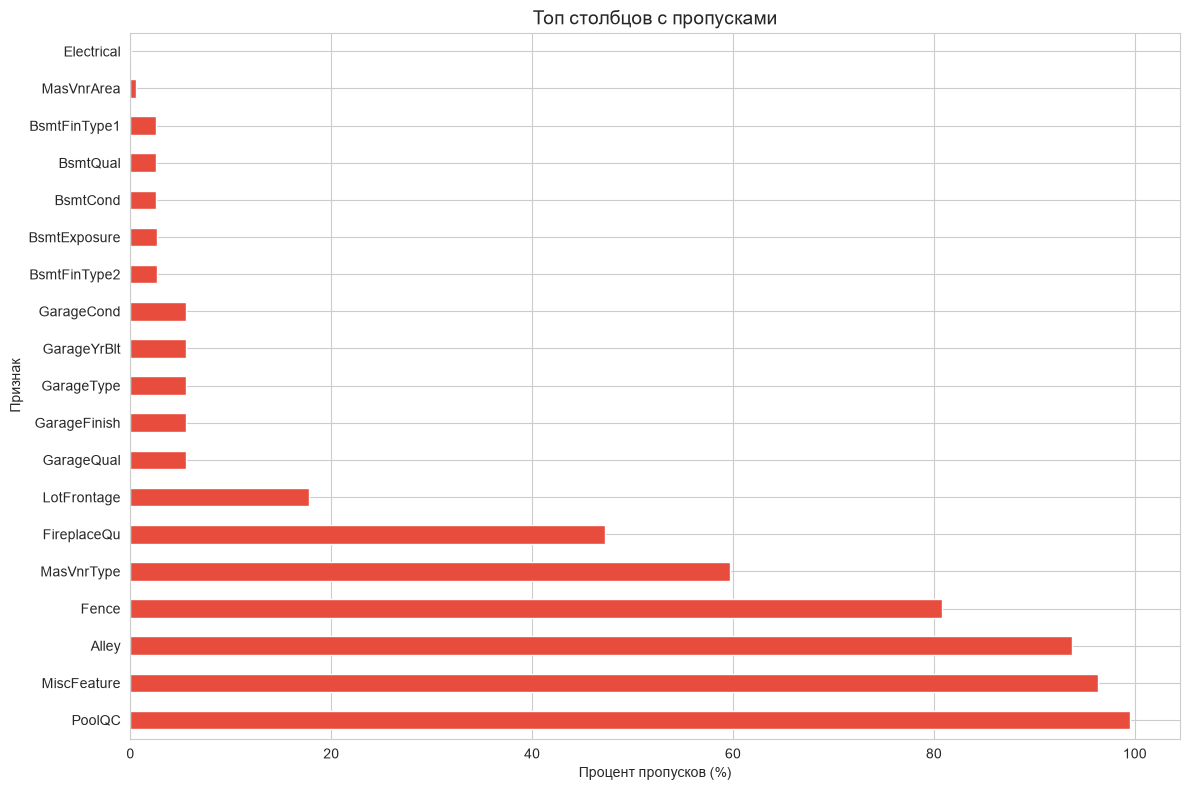

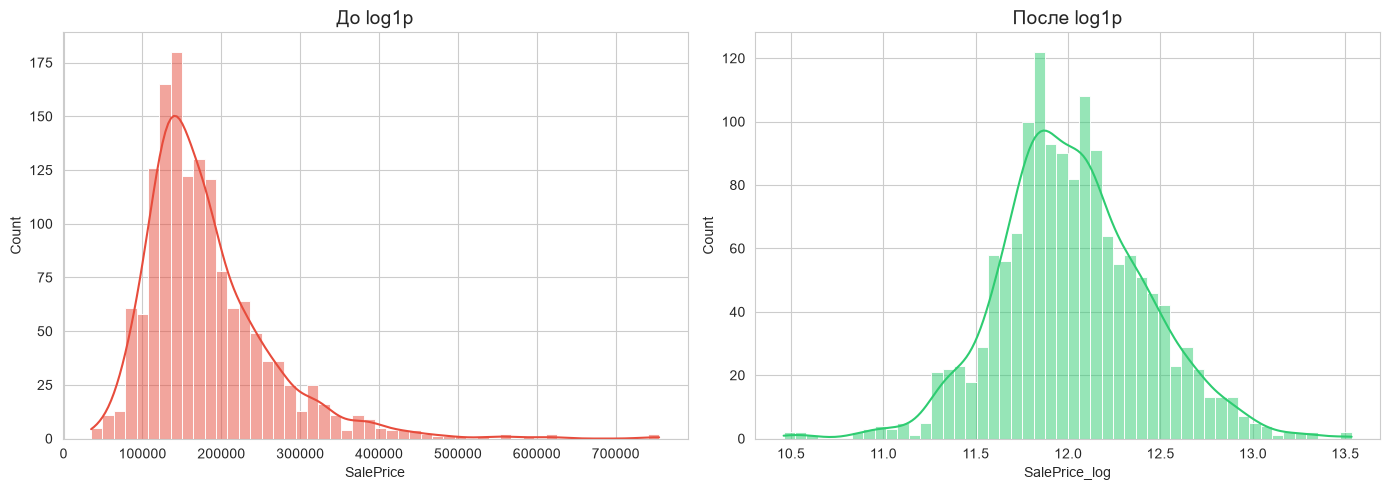

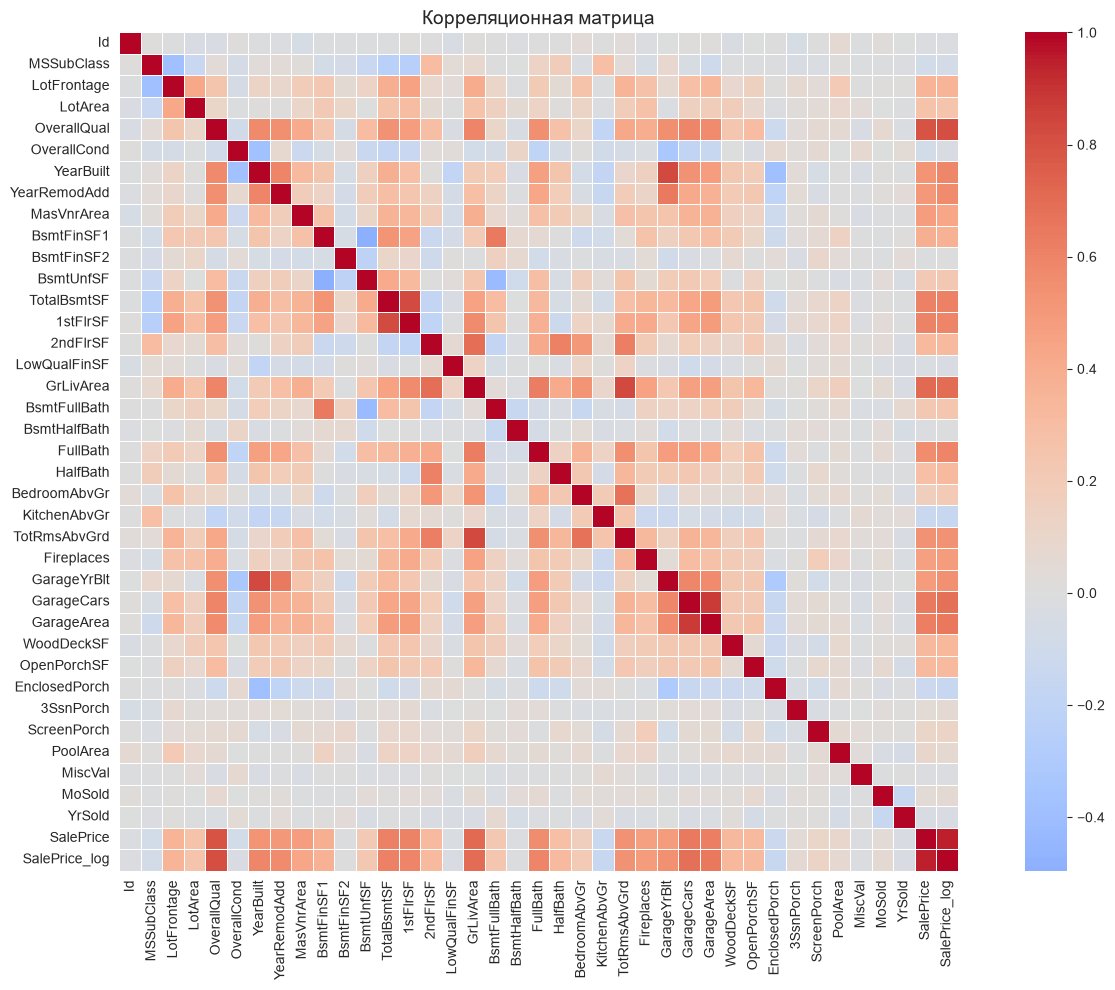

C:\Users\rimch\AppData\Local\Temp\ipykernel_17052\4202268496.py:90: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_df, x='OverallQual', y='GrLivArea', palette='viridis')


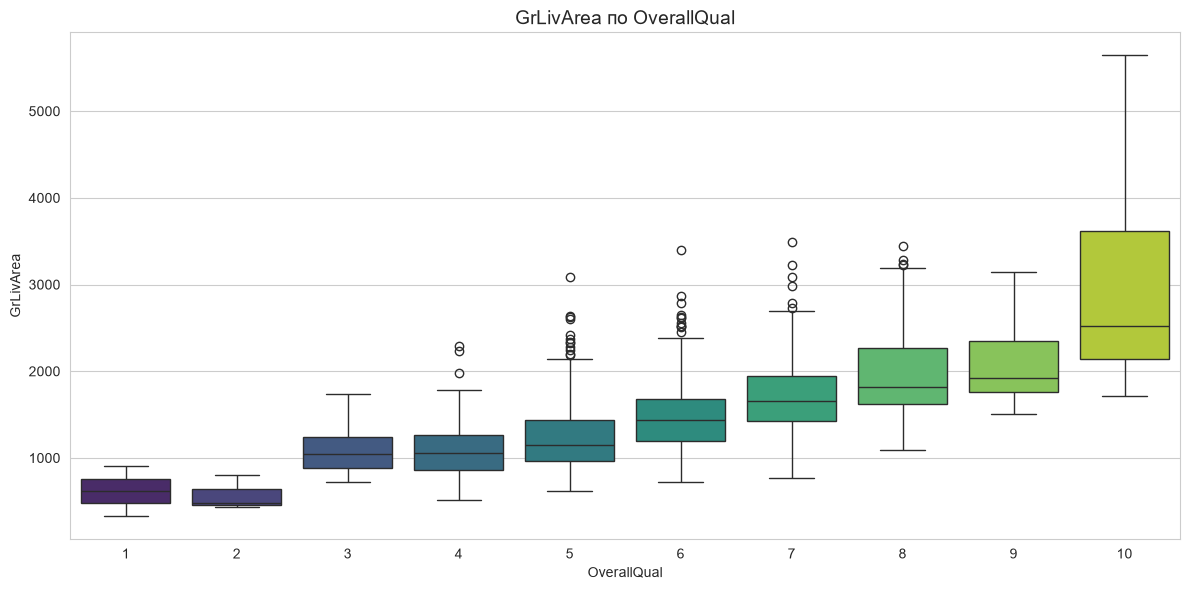

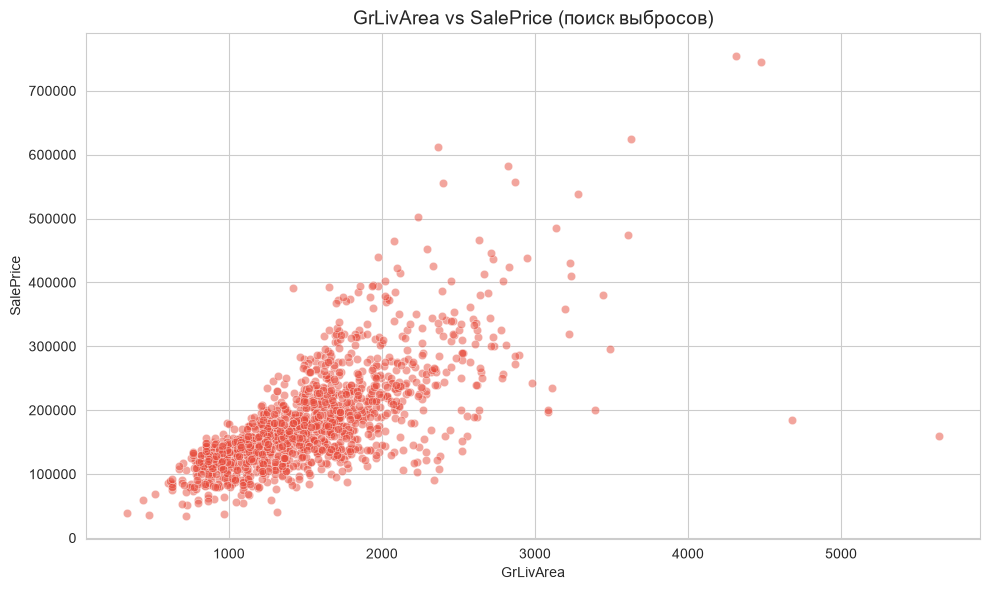

C:\Users\rimch\AppData\Local\Temp\ipykernel_17052\4202268496.py:131: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in train_df.select_dtypes(include=['object']).columns:


In [9]:
# ============================================================
# ПОЛНЫЙ КОД ПРОЕКТА — Модуль 2: «House Prices»
# ============================================================
# Разделы 1-3: титульник, введение, теория — только Markdown.
# Раздел 4: загрузка данных.
# Раздел 5: EDA и предобработка.
# Раздел 6: обучение моделей.
# Раздел 7: оценка качества.
# Раздел 8: интерпретация.
# Раздел 9: функция предсказания.
# Раздел 10: сохранение моделей.
# Раздел 11: загрузка модели.
# Раздел 12-14: выводы, источники, приложение.
# ============================================================

# --- Импорт библиотек ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import json
import time
import joblib
import requests
from io import BytesIO

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# --- Загрузка данных ---
os.makedirs('data', exist_ok=True)

if os.path.exists('train.csv') and not os.path.exists('data/train.csv'):
    os.rename('train.csv', 'data/train.csv')
if os.path.exists('test.csv') and not os.path.exists('data/test.csv'):
    os.rename('test.csv', 'data/test.csv')

train_df = pd.read_csv('data/train.csv')
test_df  = pd.read_csv('data/test.csv')

# --- EDA: анализ пропусков ---
missing = train_df.isnull().sum()
missing_pct = (missing / len(train_df)) * 100

missing_df = pd.DataFrame({
    'Пропуски': missing,
    'Процент': missing_pct
}).sort_values('Процент', ascending=False)

missing_only = missing_df[missing_df['Пропуски'] > 0]

if len(missing_only) > 0:
    plt.figure(figsize=(12, 8))
    missing_only['Процент'].plot(kind='barh', color='#e74c3c')
    plt.xlabel('Процент пропусков (%)')
    plt.ylabel('Признак')
    plt.title('Топ столбцов с пропусками', fontsize=14)
    plt.tight_layout()
    plt.show()

# --- EDA: целевая переменная + log1p ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=train_df, x='SalePrice', kde=True, bins=50,
             ax=axes[0], color='#e74c3c')
axes[0].set_title('До log1p', fontsize=14)

train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])

sns.histplot(data=train_df, x='SalePrice_log', kde=True, bins=50,
             ax=axes[1], color='#2ecc71')
axes[1].set_title('После log1p', fontsize=14)
plt.tight_layout()
plt.show()

# --- EDA: heatmap корреляций ---
plt.figure(figsize=(14, 10))
numeric_cols = train_df.select_dtypes(include=[np.number]).columns
corr_matrix = train_df[numeric_cols].corr()
sns.heatmap(corr_matrix, cmap='coolwarm', center=0,
            square=True, linewidths=0.5)
plt.title('Корреляционная матрица', fontsize=14)
plt.tight_layout()
plt.show()

# --- EDA: boxplot и scatterplot ---
plt.figure(figsize=(12, 6))
sns.boxplot(data=train_df, x='OverallQual', y='GrLivArea', palette='viridis')
plt.title('GrLivArea по OverallQual', fontsize=14)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
sns.scatterplot(data=train_df, x='GrLivArea', y='SalePrice',
                alpha=0.5, color='#e74c3c')
plt.title('GrLivArea vs SalePrice (поиск выбросов)', fontsize=14)
plt.tight_layout()
plt.show()

# --- Обработка пропусков ---
none_cols = [
    'PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
    'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
    'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
    'MasVnrType',
]
for col in none_cols:
    train_df[col] = train_df[col].fillna('None')
    test_df[col]  = test_df[col].fillna('None')

zero_cols = [
    'GarageYrBlt', 'GarageArea', 'GarageCars',
    'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
    'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea',
]
for col in zero_cols:
    train_df[col] = train_df[col].fillna(0)
    test_df[col]  = test_df[col].fillna(0)

train_df['LotFrontage'] = train_df.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median()))
test_df['LotFrontage']  = test_df.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median()))

lot_frontage_median = train_df['LotFrontage'].median()
train_df['LotFrontage'] = train_df['LotFrontage'].fillna(lot_frontage_median)
test_df['LotFrontage']  = test_df['LotFrontage'].fillna(lot_frontage_median)

for col in train_df.select_dtypes(include=['object']).columns:
    if train_df[col].isnull().sum() > 0:
        mode_value = train_df[col].mode()[0]
        train_df[col] = train_df[col].fillna(mode_value)
        test_df[col]  = test_df[col].fillna(mode_value)

for col in train_df.select_dtypes(include=[np.number]).columns:
    if train_df[col].isnull().sum() > 0:
        median_value = train_df[col].median()
        train_df[col] = train_df[col].fillna(median_value)
        test_df[col]  = test_df[col].fillna(median_value)

# --- Обработка выбросов ---
train_df = train_df[
    (train_df['GrLivArea'] < 4000) &
    (train_df['SalePrice'] < 500000)
]

# --- Feature Engineering ---
for df in [train_df, test_df]:
    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
    df['TotalBath'] = (df['FullBath'] + 0.5 * df['HalfBath'] +
                       df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath'])
    df['TotalPorch'] = (df['OpenPorchSF'] + df['EnclosedPorch'] +
                        df['3SsnPorch'] + df['ScreenPorch'] + df['WoodDeckSF'])
    df['HouseAge']    = df['YrSold'] - df['YearBuilt']
    df['RemodAge']    = df['YrSold'] - df['YearRemodAdd']
    df['IsRemodeled'] = (df['YearRemodAdd'] != df['YearBuilt']).astype(int)
    df['HasPool']      = (df['PoolArea'] > 0).astype(int)
    df['Has2ndFloor']  = (df['2ndFlrSF'] > 0).astype(int)
    df['HasGarage']    = (df['GarageArea'] > 0).astype(int)
    df['HasBsmt']      = (df['TotalBsmtSF'] > 0).astype(int)
    df['HasFireplace'] = (df['Fireplaces'] > 0).astype(int)
    df['OverallQual_TotalSF'] = df['OverallQual'] * df['TotalSF']
    df['Qual_Age']            = df['OverallQual'] / (df['HouseAge'] + 1)

# --- Кодирование порядковых признаков ---
qual_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
qual_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond',
             'HeatingQC', 'KitchenQual', 'FireplaceQu',
             'GarageQual', 'GarageCond', 'PoolQC']
for col in qual_cols:
    train_df[col] = train_df[col].map(qual_map)
    test_df[col]  = test_df[col].map(qual_map)

bsmt_exp_map = {'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4}
for col in ['BsmtExposure']:
    train_df[col] = train_df[col].map(bsmt_exp_map)
    test_df[col]  = test_df[col].map(bsmt_exp_map)

bsmt_fin_map = {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3,
                'BLQ': 4, 'ALQ': 5, 'GLQ': 6}
for col in ['BsmtFinType1', 'BsmtFinType2']:
    train_df[col] = train_df[col].map(bsmt_fin_map)
    test_df[col]  = test_df[col].map(bsmt_fin_map)

garage_fin_map = {'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3}
for col in ['GarageFinish']:
    train_df[col] = train_df[col].map(garage_fin_map)
    test_df[col]  = test_df[col].map(garage_fin_map)

func_map = {'Sal': 0, 'Sev': 1, 'Maj2': 2, 'Maj1': 3,
            'Mod': 4, 'Min2': 5, 'Min1': 6, 'Typ': 7}
for col in ['Functional']:
    train_df[col] = train_df[col].map(func_map)
    test_df[col]  = test_df[col].map(func_map)

slope_map = {'Gtl': 0, 'Mod': 1, 'Sev': 2}
for col in ['LandSlope']:
    train_df[col] = train_df[col].map(slope_map)
    test_df[col]  = test_df[col].map(slope_map)

shape_map = {'Reg': 0, 'IR1': 1, 'IR2': 2, 'IR3': 3}
for col in ['LotShape']:
    train_df[col] = train_df[col].map(shape_map)
    test_df[col]  = test_df[col].map(shape_map)

paved_map = {'N': 0, 'P': 1, 'Y': 2}
for col in ['PavedDrive']:
    train_df[col] = train_df[col].map(paved_map)
    test_df[col]  = test_df[col].map(paved_map)

for df in [train_df, test_df]:
    df['CentralAir'] = (df['CentralAir'] == 'Y').astype(int)

# --- Кодирование номинальных признаков ---
nominal_cols = [
    'MSZoning', 'Street', 'Alley', 'LandContour', 'Utilities',
    'LotConfig', 'Neighborhood', 'Condition1', 'Condition2',
    'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl',
    'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation',
    'Heating', 'GarageType', 'MiscFeature', 'Fence',
    'SaleType', 'SaleCondition', 'Electrical',
]
train_len = len(train_df)
combined = pd.concat([train_df, test_df], axis=0, ignore_index=True)
combined = pd.get_dummies(combined, columns=nominal_cols, drop_first=True)
train_df = combined.iloc[:train_len].copy()
test_df  = combined.iloc[train_len:].reset_index(drop=True).copy()

# --- Обучение моделей ---
for col in test_df.columns:
    if test_df[col].isnull().sum() > 0:
        if test_df[col].dtype == 'object':
            test_df[col] = test_df[col].fillna('None')
        else:
            test_df[col] = test_df[col].fillna(
                train_df[col].median() if col in train_df.columns else 0
            )

feature_cols = [col for col in train_df.columns
                if col not in ['Id', 'SalePrice', 'SalePrice_log']]

X = train_df[feature_cols].copy()
y = train_df['SalePrice_log'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

start = time.time()
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
lr_time = time.time() - start

start = time.time()
ridge_model = Ridge(alpha=1.0, random_state=42)
ridge_model.fit(X_train_scaled, y_train)
ridge_time = time.time() - start

start = time.time()
lasso_model = Lasso(alpha=0.0005, max_iter=10000, random_state=42)
lasso_model.fit(X_train_scaled, y_train)
lasso_time = time.time() - start

start = time.time()
enet_model = ElasticNet(alpha=0.001, l1_ratio=0.5,
                        max_iter=10000, random_state=42)
enet_model.fit(X_train_scaled, y_train)
enet_time = time.time() - start

# --- Оценка качества ---
def evaluate_model(model, X_test, y_test, model_name):
    y_pred_log = model.predict(X_test)
    y_pred_real = np.expm1(y_pred_log)
    y_test_real = np.expm1(y_test)

    rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_log))
    mae_log  = mean_absolute_error(y_test, y_pred_log)
    r2_log   = r2_score(y_test, y_pred_log)
    rmse_real = np.sqrt(mean_squared_error(y_test_real, y_pred_real))
    mae_real  = mean_absolute_error(y_test_real, y_pred_real)
    r2_real   = r2_score(y_test_real, y_pred_real)

    return {
        'name': model_name,
        'rmse_log': rmse_log, 'mae_log': mae_log, 'r2_log': r2_log,
        'rmse_real': rmse_real, 'mae_real': mae_real, 'r2_real': r2_real,
        'y_pred_log': y_pred_log
    }

results_lr    = evaluate_model(lr_model,    X_test_scaled, y_test, 'Linear Regression')
results_ridge = evaluate_model(ridge_model, X_test_scaled, y_test, 'Ridge')
results_lasso = evaluate_model(lasso_model, X_test_scaled, y_test, 'Lasso')
results_enet  = evaluate_model(enet_model,  X_test_scaled, y_test, 'ElasticNet')

best_result = min([results_lr, results_ridge, results_lasso, results_enet],
                  key=lambda r: r['rmse_log'])
best_name = best_result['name']
best_model_map = {
    'Linear Regression': lr_model,
    'Ridge':             ridge_model,
    'Lasso':             lasso_model,
    'ElasticNet':        enet_model,
}
best_model = best_model_map[best_name]

# --- Интерпретация ---
coef_df = pd.DataFrame({
    'Feature':     feature_cols,
    'Coefficient': lasso_model.coef_
}).sort_values('Coefficient', ascending=False)

n_total = len(lasso_model.coef_)
n_zero  = (lasso_model.coef_ == 0).sum()
n_used  = n_total - n_zero

# --- Функция предсказания ---
def predict_price(house_data, model=lasso_model, scaler=scaler,
                   feature_cols=feature_cols):
    TotalSF    = house_data['TotalBsmtSF'] + house_data['1stFlrSF'] + house_data['2ndFlrSF']
    TotalBath  = (house_data['FullBath'] + 0.5 * house_data['HalfBath'] +
                  house_data['BsmtFullBath'] + 0.5 * house_data['BsmtHalfBath'])
    HouseAge   = house_data['YrSold'] - house_data['YearBuilt']
    RemodAge   = house_data['YrSold'] - house_data['YearRemodAdd']
    IsRemodeled = int(house_data['YearRemodAdd'] != house_data['YearBuilt'])
    HasPool     = int(house_data['PoolArea'] > 0)
    Has2ndFloor = int(house_data['2ndFlrSF'] > 0)
    HasGarage   = int(house_data['GarageArea'] > 0)
    HasBsmt     = int(house_data['TotalBsmtSF'] > 0)
    HasFireplace = int(house_data['Fireplaces'] > 0)
    OverallQual_TotalSF = house_data['OverallQual'] * TotalSF
    Qual_Age = house_data['OverallQual'] / (HouseAge + 1)

    full_row = {col: 0 for col in feature_cols}
    numeric_values = {
        'OverallQual': house_data['OverallQual'],
        'OverallCond': house_data['OverallCond'],
        'GrLivArea':   house_data['GrLivArea'],
        'TotalBsmtSF': house_data['TotalBsmtSF'],
        '1stFlrSF':    house_data['1stFlrSF'],
        '2ndFlrSF':    house_data['2ndFlrSF'],
        'YearBuilt':   house_data['YearBuilt'],
        'YearRemodAdd':house_data['YearRemodAdd'],
        'YrSold':      house_data['YrSold'],
        'GarageArea':  house_data['GarageArea'],
        'GarageCars':  house_data['GarageCars'],
        'FullBath':    house_data['FullBath'],
        'HalfBath':    house_data['HalfBath'],
        'BsmtFullBath':house_data['BsmtFullBath'],
        'BsmtHalfBath':house_data['BsmtHalfBath'],
        'Fireplaces':  house_data['Fireplaces'],
        'PoolArea':    house_data['PoolArea'],
        'LotArea':     house_data['LotArea'],
        'TotalSF':     TotalSF,
        'TotalBath':   TotalBath,
        'HouseAge':    HouseAge,
        'RemodAge':    RemodAge,
        'IsRemodeled': IsRemodeled,
        'HasPool':     HasPool,
        'Has2ndFloor': Has2ndFloor,
        'HasGarage':   HasGarage,
        'HasBsmt':     HasBsmt,
        'HasFireplace':HasFireplace,
        'OverallQual_TotalSF': OverallQual_TotalSF,
        'Qual_Age':    Qual_Age,
    }
    for key, value in numeric_values.items():
        if key in full_row:
            full_row[key] = value

    X_new = pd.DataFrame([full_row])
    X_new_scaled = scaler.transform(X_new)
    y_pred_log = model.predict(X_new_scaled)[0]
    return np.expm1(y_pred_log)

# --- Сохранение моделей ---
os.makedirs('models', exist_ok=True)

joblib.dump(lr_model,    'models/lr_model.pkl')
joblib.dump(ridge_model, 'models/ridge_model.pkl')
joblib.dump(lasso_model, 'models/lasso_model.pkl')
joblib.dump(enet_model,  'models/enet_model.pkl')
joblib.dump(scaler,      'models/scaler.pkl')

with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

metrics = {
    'linear_regression': {
        'rmse_log':  float(results_lr['rmse_log']),
        'mae_log':   float(results_lr['mae_log']),
        'r2_log':    float(results_lr['r2_log']),
        'rmse_real': float(results_lr['rmse_real']),
        'mae_real':  float(results_lr['mae_real']),
        'r2_real':   float(results_lr['r2_real']),
        'training_time_sec': float(lr_time),
    },
    'ridge': {
        'alpha':     float(ridge_model.alpha),
        'rmse_log':  float(results_ridge['rmse_log']),
        'mae_log':   float(results_ridge['mae_log']),
        'r2_log':    float(results_ridge['r2_log']),
        'rmse_real': float(results_ridge['rmse_real']),
        'mae_real':  float(results_ridge['mae_real']),
        'r2_real':   float(results_ridge['r2_real']),
        'training_time_sec': float(ridge_time),
    },
    'lasso': {
        'alpha':     float(lasso_model.alpha),
        'rmse_log':  float(results_lasso['rmse_log']),
        'mae_log':   float(results_lasso['mae_log']),
        'r2_log':    float(results_lasso['r2_log']),
        'rmse_real': float(results_lasso['rmse_real']),
        'mae_real':  float(results_lasso['mae_real']),
        'r2_real':   float(results_lasso['r2_real']),
        'training_time_sec': float(lasso_time),
        'n_features_dropped':  int(n_zero),
        'n_features_selected': int(n_used),
    },
    'elasticnet': {
        'alpha':     float(enet_model.alpha),
        'l1_ratio':  float(enet_model.l1_ratio),
        'rmse_log':  float(results_enet['rmse_log']),
        'mae_log':   float(results_enet['mae_log']),
        'r2_log':    float(results_enet['r2_log']),
        'rmse_real': float(results_enet['rmse_real']),
        'mae_real':  float(results_enet['mae_real']),
        'r2_real':   float(results_enet['r2_real']),
        'training_time_sec': float(enet_time),
    },
    'best_model': best_name,
}

with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)

# --- Загрузка модели (проверка воспроизводимости) ---
USE_GITHUB = False
GITHUB_USERNAME = 'username'
REPO_NAME       = 'ml-course-komanich'
BASE_URL = (f'https://raw.githubusercontent.com/{GITHUB_USERNAME}/'
            f'{REPO_NAME}/main/module-2-house-prices')

if USE_GITHUB:
    response = requests.get(f'{BASE_URL}/models/lasso_model.pkl')
    response.raise_for_status()
    lasso_loaded = joblib.load(BytesIO(response.content))
    scaler_loaded = joblib.load(BytesIO(
        requests.get(f'{BASE_URL}/models/scaler.pkl').content))
    feature_cols_loaded = requests.get(
        f'{BASE_URL}/models/feature_cols.json').json()
else:
    lasso_loaded = joblib.load('models/lasso_model.pkl')
    scaler_loaded = joblib.load('models/scaler.pkl')
    with open('models/feature_cols.json', 'r', encoding='utf-8') as f:
        feature_cols_loaded = json.load(f)